# Turbomachinery Active Subspace Performance Maps: Efficiency and Pressure Ratio of a Transonic Fan Blade

__Pranay Seshadri__, Department of Engineering, University of Cambridge, Cambridge CB2 1PZ, U.K.

__Shahrokh Shahpar__, CFD Methods, Rolls-Royce plc., Derby DE24 8BJ, U.K.

__Paul Constantine__, Department of Computer Science, University of Colorado, Boulder, CO 80309

__Geoffrey Parks__, Department of Engineering, University of Cambridge, Cambridge CB2 1PZ, U.K.

__Mike Adams__, Fan and Compressor Subsystems, Rolls-Royce plc., Derby DE24 8BJ, U.K.

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

This notebook analyzes CFD results for Rolls-Royce research fan blades that the authors of Seshadri et al. [[1]][R1] published, "shared with permission from Rolls-Royce plc", in the [equadratures/data-sets](https://github.com/equadratures/data-sets) repository (`3Dfan_blades`). The archive holds three blades, A, B and C, with no statement of which one the paper used; the evidence below points to blade A, which is our inference, not a fact stated by the archive or the paper. Page, equation and figure numbers refer to the published article (J. Turbomach. 140(4):041003, 2018). The notebook runs in Python 3 with numpy, scipy and matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later, and takes under a minute (most of it in the library's pairs bootstrap, run once for comparison).

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import active_subspaces as ac
import convert_data as cd

SEED = 2018                        # the only seed in this notebook (all bootstrap replicates)
t_start = time.perf_counter()
m = 25
labels = [f'{d} {s}' for d in ('dih', 'LE', 'TE', 'swp', 'skw') for s in (0, 25, 50, 75, 100)]

### Summary

Seshadri et al. [[1]][R1] perturb a transonic research fan blade with 25 design variables (five degrees of freedom at five spanwise sections), run 3-D RANS simulations with the Rolls-Royce solver Hydra, and find two-dimensional active subspaces for cruise efficiency and cruise pressure ratio, which they turn into contour maps ("performance maps") of the design space. From the published runs of blade A (548 designs, values only), the paper's own estimator, the gradient of a least-squares quadratic in all 25 inputs, gives first eigenvectors that match the paper's bar charts ($|\mathbf w_1\cdot\mathbf w_1^{\mathrm{paper}}| = 0.992$ for efficiency, 0.988 for pressure ratio) and the same maps: an efficiency ridge with a high-efficiency corridor along the paper's vector v = (0.4, −1.6), and a pressure ratio that is almost linear in its first active variable. Efficiency is dominated by leading-edge recamber at 50–100 % span and pressure ratio by trailing-edge recamber; the paper's eigenvalue plot (Fig. 7) agrees in shape with the square roots of our eigenvalues, and the stored outputs are rescaled versions of the paper's (by factors of roughly 3 for efficiency and 4 for pressure ratio, inferred from the paper's figures, not documented), so only shapes and directions, not magnitudes, can be compared directly.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and little along $\mathbf W_2^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a contour map over $\mathbf y$ shows the design space in two dimensions. When only values of $f$ are available, $\nabla f$ is replaced by the gradient of a fitted model, here a global quadratic, as in the paper, or local linear fits, and the estimate is assessed by resampling. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

### The model

**Blade and solver** (Sec. 2.1, pp. 1–2). The research blade is a high Mach number fan blade whose pressure ratio at 95 % shaft speed is comparable to the cruise working line of modern high bypass ratio fans; its geometry is proprietary (Fig. 1 is scaled). The domain is one fan blade passage with a downstream splitter into the engine sector stators (ESS) and the outlet guide vanes (OGV). Hydra, the Rolls-Royce unstructured solver [[3]][R3], solves the steady Reynolds-averaged Navier–Stokes equations with a five-stage Runge–Kutta scheme, a block Jacobi preconditioner and the Spalart–Allmaras model with wall functions. The inlet has a total pressure and total temperature profile, both exits have non-reflective exit-capacity conditions, and the rotor, hub, casing and splitter are viscous walls (rotor and hub in the rotating frame). PADRAM [[4]][R4] makes the mesh: H blocks upstream, downstream and at the periodic boundaries, an O-mesh around the blade and a C-mesh at the splitter, 1.75 × 10⁶ cells after a mesh convergence study, with 129 points radially.

**Design variables** (Sec. 2.1, Fig. 2). PADRAM perturbs five airfoil sections, at 0, 25, 50, 75 and 100 % span, and interpolates linearly between them. Each section has five degrees of freedom: dihedral (axial movement), sweep (tangential displacement), leading-edge (LE) recambering, trailing-edge (TE) recambering and skew (rotation about the centroidal axis). They do not change the blade thickness. That makes $m = 25$ inputs, each uniform between bounds $\hat x_L$ and $\hat x_U$ chosen so that part of the space emulates manufacturing variations and part suits design optimization. The bounds are not published; the analysis uses the normalized inputs (Eq. 2)

$$
x_j = \frac{2\hat x_j - (\hat x_{U,j} + \hat x_{L,j})}{\hat x_{U,j} - \hat x_{L,j}} \in [-1, 1],
$$

with $\mathbf x = 0$ the research blade. (The paper prints the numerator as $2\hat x_j - (\hat x_{U,j} - \hat x_{L,j})$, which does not map $[\hat x_{L,j}, \hat x_{U,j}]$ onto $[-1, 1]$; we use the evident intent.) The columns follow the order of the paper's eigenvector bar charts (Figs. 8(b), 13(b)): dihedral, LE recamber, TE recamber, sweep, skew, each at the five spans in order. (Sec. 2.1 lists the degrees of freedom in a different order; the check below shows the bar-chart order is the one in the file.)

**Quantities of interest** (Sec. 3, p. 3). At cruise (95 % shaft speed) the cruise geometry, which differs from the climb geometry through blade untwist, is run on the working line, and

$$
\eta = 100\,\frac{\mathrm{PR}^{(\gamma - 1)/\gamma} - 1}{\mathrm{TR} - 1}
$$

(Eq. 1) is the adiabatic efficiency, with PR and TR the total pressure and total temperature ratios mass-averaged over the ESS and OGV exits and $\gamma$ the ratio of specific heats. The second quantity is PR itself. The paper's third quantity, maximum climb flow capacity at 105 % speed, and its efficiency–sensitivity (Sec. 5) are not in the published data. The archive's outputs are "non-dimensional efficiency" and "non-dimensional pressure ratio". Their sample means are zero to rounding in every blade, so they are deviations from the blade's sample mean, and their scale is not documented. The paper's figures suggest the archive's values are the paper's divided by roughly 3 (efficiency, in %) and roughly 4 (pressure ratio); see the eigenvalue comparisons below.

**Estimator in the paper** (Sec. 3.2.1, Eqs. 6–11). A quadratic $f(\mathbf x) = \mathbf x^T\mathbf A\mathbf x + \mathbf c^T\mathbf x + d$ with 1 + 25 + 325 = 351 coefficients is fitted by least squares to $N = 500$ runs (an optimal Latin hypercube of 150 plus 350 more), and $\mathbf C$ is the average of $\nabla f\nabla f^T$ over the uniform density on $[-1, 1]^{25}$. The paper prints Eq. 11 as $\mathbf C = \tfrac13\mathbf A^2 + \mathbf c\mathbf c^T$; for $f = \mathbf x^T\mathbf A\mathbf x + \dots$ the gradient is $2\mathbf A\mathbf x + \mathbf c$ and the average is $\tfrac43\mathbf A^2 + \mathbf c\mathbf c^T$. We use the latter, which the library computes, and compare both with the paper's Fig. 7 below. The paper takes $n = 2$ for both quantities.

The cell lists the inputs. Nominal values are 0 (the research blade); the physical bounds are unknown.

In [2]:
print(f"{'j':>2s}  {'name':16s} {'DOF':22s} {'span':>5s} {'lower':>6s} {'upper':>6s} {'nominal':>8s}")
dof_long = {'dihedral': 'dihedral (axial)', 'le_recamber': 'LE recamber', 'te_recamber': 'TE recamber',
            'sweep': 'sweep (tangential)', 'skew': 'skew (rotation)'}
for j, n in enumerate(cd.NAMES):
    dof, span = n.rsplit('_', 1)
    print(f'{j + 1:2d}  {n:16s} {dof_long[dof]:22s} {int(span):4d}% {cd.LOWER[j]:6.0f} {cd.UPPER[j]:6.0f} {0:8.0f}')

 j  name             DOF                     span  lower  upper  nominal
 1  dihedral_000     dihedral (axial)          0%     -1      1        0
 2  dihedral_025     dihedral (axial)         25%     -1      1        0
 3  dihedral_050     dihedral (axial)         50%     -1      1        0
 4  dihedral_075     dihedral (axial)         75%     -1      1        0
 5  dihedral_100     dihedral (axial)        100%     -1      1        0
 6  le_recamber_000  LE recamber               0%     -1      1        0
 7  le_recamber_025  LE recamber              25%     -1      1        0
 8  le_recamber_050  LE recamber              50%     -1      1        0
 9  le_recamber_075  LE recamber              75%     -1      1        0
10  le_recamber_100  LE recamber             100%     -1      1        0
11  te_recamber_000  TE recamber               0%     -1      1        0
12  te_recamber_025  TE recamber              25%     -1      1        0
13  te_recamber_050  TE recamber              50%  

### Load data

`convert_data.py` copied the archive's nine arrays losslessly into one CSV per blade (see `DATA.md`): 25 normalized inputs, then non-dimensional efficiency (`eta_nd`) and non-dimensional pressure ratio (`pr_nd`). We keep every row; no run in the archive is flagged as failed, and all values are finite. The cell also checks the designs: duplicates, overlaps between blades, the extent of each design, and whether it is a Latin hypercube (one point per stratum of width $1/M$ in every column).

In [3]:
data = {b: np.loadtxt(f'blade_{b}.csv', delimiter=',') for b in 'ABC'}
for b, a in data.items():
    print(f'blade {b}: {a.shape} -> X {a[:, :m].shape}, eta {a[:, m].shape}, PR {a[:, m + 1].shape}')
XA, etaA, prA = data['A'][:, :m], data['A'][:, m], data['A'][:, m + 1]

# checks on the stored designs and outputs
for b, a in data.items():
    X = a[:, :m]
    U = (X + 1) / 2
    M = len(X)
    most = max(np.bincount(np.minimum((U[:, j] * M).astype(int), M - 1), minlength=M).max() for j in range(m))
    z = (X - X.mean(0)) / X.std(0)
    kurt = (z**4).mean(0)
    print(f'blade {b}: {len(np.unique(X, axis=0))} distinct rows; x in [{X.min():.4f}, {X.max():.4f}]; '
          f'rows with max|x_j| <= 0.40: {np.sum(np.abs(X).max(1) <= 0.40)}; all-zero rows: {np.sum(~X.any(1))}; '
          f'most points in one 1/{M} stratum of a column: {most} (a Latin hypercube has 1); '
          f'kurtosis {kurt.min():.2f}-{kurt.max():.2f}; mean eta {a[:, m].mean():.1e}, mean PR {a[:, m + 1].mean():.1e}')
rows = {b: {tuple(r) for r in data[b][:, :m]} for b in 'ABC'}
print(f'designs shared: A-B {len(rows["A"] & rows["B"])}, A-C {len(rows["A"] & rows["C"])}, '
      f'B-C {len(rows["B"] & rows["C"])}')
inner = np.abs(XA).max(1) <= 0.40
print(f'blade A: {np.sum(~inner)} designs with max|x_j| in [{np.abs(XA[~inner]).max(1).min():.2f}, 1], '
      f'{inner.sum()} designs with max|x_j| in [{np.abs(XA[inner]).max(1).min():.2f}, {np.abs(XA[inner]).max():.4f}]')
print(f'blade A: rows sorted by x1: {bool(np.all(np.diff(XA[:, 0]) >= 0))}')
print(f'blade A: eta in [{etaA.min():.4f}, {etaA.max():.4f}] (range {np.ptp(etaA):.2f}), s.d. {etaA.std(ddof=1):.4f}; '
      f'PR in [{prA.min():.5f}, {prA.max():.5f}], s.d. {prA.std(ddof=1):.5f}')

blade A: (548, 27) -> X (548, 25), eta (548,), PR (548,)
blade B: (311, 27) -> X (311, 25), eta (311,), PR (311,)
blade C: (547, 27) -> X (547, 25), eta (547,), PR (547,)
blade A: 548 distinct rows; x in [-0.9999, 0.9998]; rows with max|x_j| <= 0.40: 90; all-zero rows: 0; most points in one 1/548 stratum of a column: 8 (a Latin hypercube has 1); kurtosis 1.94-2.18; mean eta 7.3e-14, mean PR -1.5e-16
blade B: 311 distinct rows; x in [-0.9999, 0.9997]; rows with max|x_j| <= 0.40: 1; all-zero rows: 1; most points in one 1/311 stratum of a column: 7 (a Latin hypercube has 1); kurtosis 1.65-1.98; mean eta -8.7e-14, mean PR 1.7e-17
blade C: 547 distinct rows; x in [-0.9999, 0.9997]; rows with max|x_j| <= 0.40: 0; all-zero rows: 0; most points in one 1/547 stratum of a column: 7 (a Latin hypercube has 1); kurtosis 1.75-1.96; mean eta 4.5e-14, mean PR 9.1e-16
designs shared: A-B 0, A-C 0, B-C 307
blade A: 458 designs with max|x_j| in [0.76, 1], 90 designs with max|x_j| in [0.33, 0.4000]
blade 

The archive holds 548 designs for blade A, 311 for B and 547 for C, with no duplicates within a blade. Blades B and C share 307 designs, and B contains $\mathbf x = 0$; blade A shares none. None of the designs is a Latin hypercube: in some column a stratum of width $1/M$ holds 8 points (blade A) or 7 (B and C), where a Latin hypercube has one. Blade A is a mixture: 458 designs fill $[-1, 1]^{25}$ (largest $|x_j|$ of each between 0.76 and 1) and 90 lie in $[-0.4, 0.4]^{25}$ (largest $|x_j|$ between 0.33 and 0.40), which makes its marginals peaked (kurtosis 1.94–2.18, against 1.8 for a uniform). Its rows are sorted by $x_1$, so the paper's 150 + 350 split cannot be recovered. The paper describes 500 optimal Latin hypercube designs (Sec. 3.1.1, 3.2.1), so blade A is not exactly the paper's design either; the evidence that it is the paper's blade comes from the results below. The stored outputs have sample mean zero to $10^{-13}$.

### Estimate the subspace

The data hold values only. We follow the paper and estimate $\mathbf C$ from the least-squares quadratic in all 25 inputs, the library's **global quadratic estimator** (`estimator="qphd"`): it fits $q(\mathbf x) = c + \mathbf g^T\mathbf x + \tfrac12\mathbf x^T\mathbf H\mathbf x$ and returns $\mathbf C = \mathbf g\mathbf g^T + \mathbf H\boldsymbol\Sigma\mathbf H$, $\boldsymbol\Sigma = \tfrac13\mathbf I$, which is exactly $\mathbb E[\nabla q\,\nabla q^T]$ for the uniform density on the cube (the paper's Eq. 10 with its quadratic). The library warns (`ValidityWarning`) that the interpretation of $\mathbf g$ and $\mathbf H$ as average gradient and Hessian of $f$ needs Gaussian inputs (Li [[7]][R7]); the matrix is still the active subspace of the fitted quadratic, which is what the paper computes. All 548 designs of blade A enter the fit; since $\mathbf C$ is computed analytically for the uniform density, the 90 inner designs only add regression points, and the cell repeats the estimate on the 458 outer designs alone.

Two caveats about sample size. First, 548 runs for 351 coefficients is 1.56 per coefficient, below the factor of 2 we would ask of a new design (the paper used 500, a factor of 1.42); the cell prints the leave-one-out (LOO) $R^2$ of the quadratic to show how well it predicts. Second, the library's bootstrap resamples rows with replacement, and a replicate of 548 rows has on average about 347 distinct rows (the cell prints the spread), so about two thirds of the replicate fits are rank-deficient (the library then uses the minimum-norm solution) and the rest are nearly singular. The cell runs the library's bootstrap once, with 200 replicates, to show the result: its bands do not even contain the full-sample eigenvalues. We therefore assess the estimate with a **wild bootstrap** of the quadratic (Wu [[5]][R5]; Rademacher weights as in Liu [[8]][R8]): the inputs are held fixed, replicate data are $q(\mathbf x_i) + v_i\,e_i/\sqrt{1 - h_{ii}}$ with $e_i$ the residuals, $h_{ii}$ the leverages and $v_i = \pm1$ with equal probability, and $\mathbf C$ is recomputed for each of 500 replicates (seed `SEED`). Three limits apply. The residuals here are mostly the deterministic misfit of a quadratic to the CFD, not noise, so the replicates measure how much perturbations of that size move the estimate. The design is held fixed, so the spread leaves out the design-to-design variability that probably separates the archive's runs from the paper's. And each replicate adds a positive-semidefinite term to $\mathbf C$, so small eigenvalues are biased upward in the replicates: the 2.5–97.5 % replicate range is not a confidence interval for them (the next cells print where it misses the estimate). The cell checks that its numpy matrix equals the library's. Eigenvector signs are set to agree with the paper's bar charts (`ac.orient(..., by="reference")`), so active coordinates can be compared with the paper's maps.

In [4]:
# Values read from the paper's figures by pixel measurement (bars to about +-0.01, eigenvalues to about 3 %).
paper = {
    'eta_eig': np.array([0.985, 0.245, 0.158, 0.15, 0.144, 0.118, 0.113, 0.0944, 0.0928, 0.0799, 0.0734, 0.066,
                         0.0589, 0.0555, 0.049, 0.0475, 0.041, 0.0383, 0.0342, 0.0274, 0.0254, 0.0175, 0.012,
                         0.0114, 0.0057]),                                     # Fig. 7(a)
    'pr_eig': np.array([0.0357, 0.00687, 0.00147, 0.00132, 0.00119, 0.00105, 0.000977, 0.000929, 0.000856,
                        0.00081, 0.000742, 0.000667, 0.000557, 0.000513, 0.000466, 0.000439, 0.000361, 0.000346,
                        0.000318, 0.000272, 0.000256, 0.000178, 0.000153, 0.00011, 6.58e-05]),   # Fig. 7(b)
    'eta_W': np.array([[-0.02, 0.02, 0.01, -0.05, -0.02, 0.00, -0.14, -0.31, -0.63, -0.51, -0.01, -0.08, -0.12,
                        -0.27, -0.32, -0.01, 0.00, -0.04, -0.03, 0.00, -0.02, 0.00, 0.03, 0.07, 0.03],
                       [0.03, 0.00, 0.01, 0.12, -0.09, 0.02, 0.07, 0.29, 0.31, 0.06, -0.11, 0.03, -0.04, -0.47,
                        -0.66, -0.04, -0.10, 0.16, 0.09, 0.18, 0.05, 0.01, -0.11, 0.03, -0.04]]).T,   # Fig. 8(b)
    'pr_W': np.array([[0.00, -0.01, 0.00, 0.00, 0.00, 0.00, 0.04, 0.09, 0.19, 0.20, -0.06, -0.21, -0.35, -0.61,
                       -0.56, 0.00, 0.00, -0.01, -0.01, -0.02, 0.00, -0.03, -0.06, -0.11, -0.12],
                      [0.01, -0.03, -0.03, 0.02, 0.02, -0.02, 0.14, 0.32, 0.65, 0.54, 0.00, 0.02, 0.03, 0.20, 0.27,
                       0.04, 0.00, 0.02, 0.02, -0.02, 0.00, -0.03, -0.05, -0.13, -0.09]]).T,       # Fig. 13(b)
}
for q in ('eta', 'pr'):
    paper[q + '_W'] = paper[q + '_W'] / np.linalg.norm(paper[q + '_W'], axis=0)   # unit columns
# Contour maps with a stated spacing (captions): Fig. 9(a) efficiency, 0.2 % between lines (p. 5);
# Fig. 16(a) pressure ratio, 0.005 between lines (p. 7). Fill levels counted in the embedded images
# (by eye and by colour clustering): about 15-18 and 20-21.
paper['eta_levels'], paper['pr_levels'] = (15, 18), (20, 21)
paper['eta_spacing'], paper['pr_spacing'] = 0.2, 0.005


def quad_design(Xn):
    """Columns 1, x_j, x_j^2, x_j x_k (j < k): the library's QPHD basis, 351 columns for m = 25."""
    j, k = np.triu_indices(Xn.shape[1], k=1)
    return np.column_stack([np.ones(len(Xn)), Xn, Xn**2, Xn[:, j] * Xn[:, k]])


def qphd_matrix(coef, m):
    """C = g g^T + H Sigma H with Sigma = I/3 (uniform on [-1, 1]^m), as in ac's QPHD."""
    g = coef[1:m + 1]
    H = np.diag(2.0 * coef[m + 1:2 * m + 1])
    j, k = np.triu_indices(m, k=1)
    H[j, k] = H[k, j] = coef[2 * m + 1:]
    return np.outer(g, g) + H @ H / 3.0


def wild_bootstrap(Xn, f, W_ref, nboot, seed):
    """Wild (Rademacher) residual bootstrap of the QPHD matrix with X held fixed.

    Replicate data are q(x_i) + v_i e_i / sqrt(1 - h_ii), with q the least-squares quadratic,
    e_i its residuals, h_ii the leverages and v_i = +-1. Returns the replicate eigenvalues,
    the subspace distances to W_ref for k = 1..m-1, and the first two eigenvectors
    sign-aligned with W_ref.
    """
    M, m = Xn.shape
    P = quad_design(Xn)
    Q, R = np.linalg.qr(P)
    h = np.sum(Q**2, axis=1)
    fit = Q @ (Q.T @ f)
    e = (f - fit) / np.sqrt(1.0 - h)
    gen = np.random.default_rng(seed)
    lam = np.empty((nboot, m)); dist = np.empty((nboot, m - 1)); W2 = np.empty((nboot, m, 2))
    for b in range(nboot):
        fb = fit + gen.choice([-1.0, 1.0], size=M) * e
        lb, Wb = np.linalg.eigh(qphd_matrix(np.linalg.solve(R, Q.T @ fb), m))
        lb, Wb = lb[::-1], Wb[:, ::-1]
        lam[b] = lb
        Pm = W_ref.T @ Wb
        dist[b] = [np.linalg.norm(Pm[:k, k:], 2) for k in range(1, m)]
        W2[b] = Wb[:, :2] * np.sign(np.sum(Wb[:, :2] * W_ref[:, :2], axis=0))
    return lam, dist, W2, h


space = ac.Uniform(cd.LOWER, cd.UPPER, names=list(cd.NAMES))
P_A = quad_design(space.to_normalized(XA))
print(f'quadratic basis: {P_A.shape[1]} terms, M = {len(XA)} runs ({len(XA) / P_A.shape[1]:.2f} per term); '
      f'2 x terms = {2 * P_A.shape[1]}; the paper: 500 runs ({500 / P_A.shape[1]:.2f} per term)')
print(f'a pairs-bootstrap replicate of {len(XA)} rows has on average {len(XA) * (1 - (1 - 1 / len(XA))**len(XA)):.1f} '
      f'distinct rows, fewer than {P_A.shape[1]} terms')
_g = np.random.default_rng(SEED)
_nd = np.array([len(np.unique(_g.integers(0, len(XA), len(XA)))) for _ in range(2000)])
print(f'  in 2000 simulated replicates: {_nd.mean():.1f} +- {_nd.std():.1f} distinct rows; '
      f'{np.mean(_nd >= P_A.shape[1]):.1%} have >= {P_A.shape[1]}')

NBOOT = 500
res = {}
for q, f in [('eta', etaA), ('pr', prA)]:
    t0 = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        sub = ac.active_subspace(space=space, X=XA, f=f, estimator='qphd')
    ks, crit, k_hat = ac.dimension_criterion(sub, rule='evg')
    sub = ac.orient(sub, by='reference', reference=paper[q + '_W'], columns=2)   # signs as in the paper's bars
    coef = np.linalg.lstsq(P_A, f, rcond=None)[0]
    lam_np = np.sort(np.linalg.eigvalsh(qphd_matrix(coef, m)))[::-1]
    g = coef[1:m + 1]
    H = np.diag(2.0 * coef[m + 1:2 * m + 1]); j_, k_ = np.triu_indices(m, k=1); H[j_, k_] = H[k_, j_] = coef[2 * m + 1:]
    lam_eq11 = np.sort(np.linalg.eigvalsh(np.outer(g, g) + H @ H / 12.0))[::-1]   # paper's Eq. 11 as printed
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        sub_out = ac.active_subspace(space=space, X=XA[~inner], f=f[~inner], estimator='qphd')
    lamb, distb, Wb, h = wild_bootstrap(space.to_normalized(XA), f, sub.W, NBOOT, SEED)
    # the library's pairs bootstrap, once, to show why it is not used here
    with warnings.catch_warnings(record=True) as cpb:
        warnings.simplefilter('always')
        sub_pb = ac.active_subspace(space=space, X=XA, f=f, estimator='qphd', nboot=200, rng=SEED)
    n_rd = sum(w.message.details.get('replicates', 0) for w in cpb
               if getattr(w.message, 'code', '') == 'accuracy.rank_deficient')
    pb_lo, pb_hi = np.percentile(sub_pb.bootstrap_eigenvalues, [2.5, 97.5], axis=0)
    quad = ac.fit_surrogate(X=XA, f=f, space=space, subspace=None, kind='poly', degree=2)
    res[q] = dict(sub=sub, lam=sub.eigenvalues, k_hat=k_hat, lamb=lamb, distb=distb, Wb=Wb, quad=quad,
                  lam_eq11=lam_eq11)
    lam = sub.eigenvalues
    print(f'\n{q}: QPHD, {NBOOT} wild-bootstrap and 200 library pairs-bootstrap replicates in {time.perf_counter() - t0:.1f} s; library warnings: '
          + '; '.join(sorted({type(w.message).__name__ for w in caught})))
    print(f'  max |library - numpy| eigenvalue difference / lambda_1: {np.abs(lam - lam_np).max() / lam[0]:.1e}; '
          f'leverages {h.min():.3f}-{h.max():.3f}')
    print(f'  quadratic in all 25 inputs: in-sample R^2 {1 - np.sum((f - P_A @ np.linalg.lstsq(P_A, f, rcond=None)[0])**2) / np.sum((f - f.mean())**2):.4f}, '
          f'LOO R^2 {quad.loo_r_squared:.4f}')
    print('  eigenvalues 1-6:', np.array2string(lam[:6], precision=3), f'... lambda_25 = {lam[-1]:.2e}')
    print(f'  lambda_1/lambda_2 = {lam[0] / lam[1]:.1f}, lambda_2/lambda_3 = {lam[1] / lam[2]:.2f}, '
          f'lambda_3/lambda_4 = {lam[2] / lam[3]:.2f}; eigenvalue-gap rule picks n = {k_hat}')
    print(f'  library pairs bootstrap (200 replicates, for comparison only): {n_rd} replicate fits rank-deficient '
          f'(min-norm solution); lambda_1 band [{pb_lo[0]:.3g}, {pb_hi[0]:.3g}], lambda_2 band [{pb_lo[1]:.3g}, {pb_hi[1]:.3g}] '
          f'(estimates {sub.eigenvalues[0]:.3g}, {sub.eigenvalues[1]:.3g}); mean subspace distance k = 1: '
          f'{sub_pb.bootstrap_distances.mean(0)[0]:.3f} (wild bootstrap: {distb.mean(0)[0]:.3f})')
    print(f'  leverages above 0.5: {np.sum(h > 0.5)} of {len(h)}')
    lo_ = sub_out.eigenvalues
    print(f'  QPHD on the {np.sum(~inner)} outer designs only: lambda_1/lambda_2 = {lo_[0] / lo_[1]:.1f}, '
          f'lambda_2/lambda_3 = {lo_[1] / lo_[2]:.2f}, |w1 . w1| = {abs(sub_out.W[:, 0] @ sub.W[:, 0]):.4f}, '
          f'|w2 . w2| = {abs(sub_out.W[:, 1] @ sub.W[:, 1]):.4f}')

quadratic basis: 351 terms, M = 548 runs (1.56 per term); 2 x terms = 702; the paper: 500 runs (1.42 per term)
a pairs-bootstrap replicate of 548 rows has on average 346.6 distinct rows, fewer than 351 terms


  in 2000 simulated replicates: 346.9 +- 7.3 distinct rows; 31.3% have >= 351



eta: QPHD, 500 wild-bootstrap and 200 library pairs-bootstrap replicates in 8.7 s; library warnings: ValidityWarning
  max |library - numpy| eigenvalue difference / lambda_1: 2.5e-16; leverages 0.057-0.887
  quadratic in all 25 inputs: in-sample R^2 0.9960, LOO R^2 0.9423
  eigenvalues 1-6: [0.111 0.006 0.001 0.001 0.001 0.001] ... lambda_25 = 2.02e-06
  lambda_1/lambda_2 = 18.6, lambda_2/lambda_3 = 4.05, lambda_3/lambda_4 = 1.66; eigenvalue-gap rule picks n = 1
  library pairs bootstrap (200 replicates, for comparison only): 135 replicate fits rank-deficient (min-norm solution); lambda_1 band [0.115, 1.4], lambda_2 band [0.0149, 1.01] (estimates 0.111, 0.00598); mean subspace distance k = 1: 0.398 (wild bootstrap: 0.052)
  leverages above 0.5: 457 of 548
  QPHD on the 458 outer designs only: lambda_1/lambda_2 = 18.2, lambda_2/lambda_3 = 3.79, |w1 . w1| = 0.9999, |w2 . w2| = 0.9951



pr: QPHD, 500 wild-bootstrap and 200 library pairs-bootstrap replicates in 7.4 s; library warnings: ValidityWarning
  max |library - numpy| eigenvalue difference / lambda_1: 5.0e-16; leverages 0.057-0.887
  quadratic in all 25 inputs: in-sample R^2 0.9996, LOO R^2 0.9937
  eigenvalues 1-6: [8.094e-05 2.242e-06 1.208e-07 9.856e-08 7.912e-08 6.136e-08] ... lambda_25 = 7.21e-11
  lambda_1/lambda_2 = 36.1, lambda_2/lambda_3 = 18.55, lambda_3/lambda_4 = 1.23; eigenvalue-gap rule picks n = 1
  library pairs bootstrap (200 replicates, for comparison only): 135 replicate fits rank-deficient (min-norm solution); lambda_1 band [7.87e-05, 0.000159], lambda_2 band [2.58e-06, 9.94e-05] (estimates 8.09e-05, 2.24e-06); mean subspace distance k = 1: 0.136 (wild bootstrap: 0.016)
  leverages above 0.5: 457 of 548
  QPHD on the 458 outer designs only: lambda_1/lambda_2 = 37.5, lambda_2/lambda_3 = 16.24, |w1 . w1| = 1.0000, |w2 . w2| = 0.9995


The quadratic fits the efficiency with in-sample $R^2 = 0.9960$ but LOO $R^2 = 0.9423$, and the pressure ratio with 0.9996 and 0.9937: the efficiency quadratic is over-parameterized for 548 runs, though it still predicts well. Both quantities have one dominant eigenvalue: $\lambda_1/\lambda_2 = 18.6$ for efficiency and 36.1 for pressure ratio, and the eigenvalue-gap rule picks $n = 1$ for both. The second gap is 4.05 for efficiency and 18.55 for pressure ratio, so a second direction is clearly separated for pressure ratio and less so for efficiency. Leaving out the 90 inner designs changes little ($|\mathbf w_1\cdot\mathbf w_1| \ge 0.9999$, $|\mathbf w_2\cdot\mathbf w_2| \ge 0.9951$). The library's pairs bootstrap fails as expected: 135 of 200 replicate fits are rank-deficient, and its band for the efficiency $\lambda_1$, $[0.115, 1.4]$, excludes the estimate 0.111 (pressure ratio: $\lambda_2$ band $[2.58\times10^{-6}, 9.94\times10^{-5}]$ against $2.24\times10^{-6}$); its mean $k = 1$ subspace distances, 0.398 and 0.136, are about 8 times the wild bootstrap's 0.052 and 0.016. Of the 548 leverages, 457 exceed 0.5.

### Results: cruise efficiency

**Eigenvalues.** Left: the eigenvalues with the 2.5–97.5 % range of the wild-bootstrap replicates. Right: the paper's Fig. 7(a), read from the figure by pixel measurement (log scale, to about 3 %), divided by its first value, against our $\lambda_k/\lambda_1$ and $\sqrt{\lambda_k/\lambda_1}$.

eta: 2.5-97.5 % replicate range lambda_1 [0.105, 0.119]; lambda_2 [0.00534, 0.00832]; lambda_3 [0.00177, 0.00408]
eta: bootstrap lambda_1/lambda_2 2.5-97.5 %: [13.0, 21.1]
eta: paper Fig. 7 ratios p1/p2 = 4.02, p2/p3 = 1.55; their squares 16.2, 2.4
eta: rms log10 difference from Fig. 7 over 25 values: lambda/lambda_1 1.602, sqrt(lambda/lambda_1) 0.157; with the printed Eq. 11, sqrt 0.369; paper first value / sqrt(lambda_1) = 2.96
eta: estimate below the 2.5 % replicate percentile for 19 of 25 eigenvalues (smallest such k = 3: 0.00148 against [0.00177, 0.00408]); estimate / replicate mean, k = 1-4: 0.994, 0.887, 0.557, 0.439
eta: contour map with 0.2 % spacing, 15-18 fill levels: paper range about 2.8-3.6 %; archive range 1.052; ratio 2.66-3.42


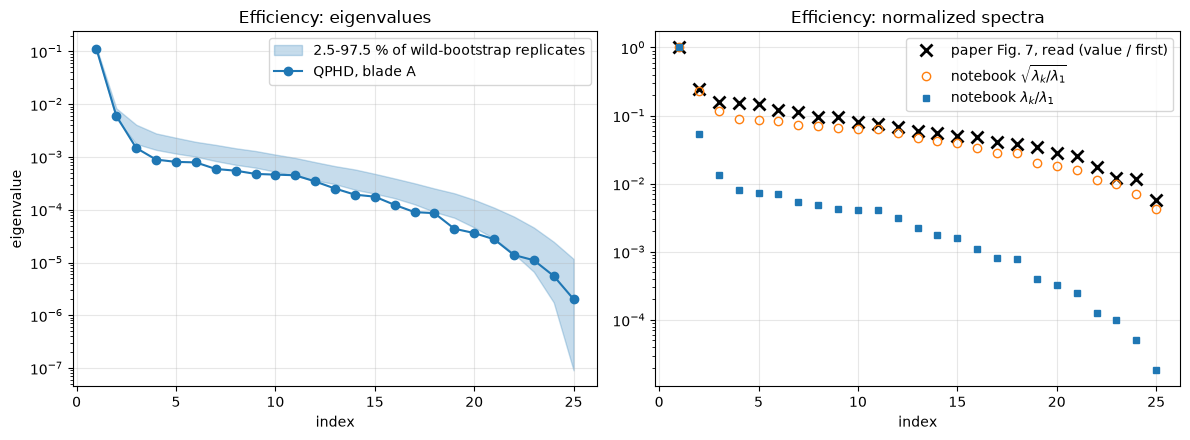

In [5]:
def eig_figure(q, title):
    r = res[q]
    lam, lamb = r['lam'], r['lamb']
    lo, hi = np.percentile(lamb, [2.5, 97.5], axis=0)
    k = np.arange(1, m + 1)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5))
    a1.fill_between(k, lo, hi, color='C0', alpha=0.25, label='2.5-97.5 % of wild-bootstrap replicates')
    a1.semilogy(k, lam, 'o-', color='C0', label='QPHD, blade A')
    a1.set_xlabel('index'); a1.set_ylabel('eigenvalue'); a1.set_title(f'{title}: eigenvalues')
    a1.grid(True, alpha=0.3); a1.legend()
    p = paper[q + '_eig']
    a2.semilogy(k, p / p[0], 'kx', ms=8, mew=2, label='paper Fig. 7, read (value / first)')
    a2.semilogy(k, np.sqrt(lam / lam[0]), 'o', color='C1', mfc='none', label='notebook $\\sqrt{\\lambda_k/\\lambda_1}$')
    a2.semilogy(k, lam / lam[0], 's', color='C0', ms=4, label='notebook $\\lambda_k/\\lambda_1$')
    a2.set_xlabel('index'); a2.set_title(f'{title}: normalized spectra'); a2.grid(True, alpha=0.3); a2.legend()
    fig.tight_layout(); plt.close(fig)
    rms = lambda v: np.sqrt(np.mean((np.log10(v / v[0]) - np.log10(p / p[0]))**2))
    print(f'{q}: 2.5-97.5 % replicate range ' + '; '.join(f'lambda_{i + 1} [{lo[i]:.3g}, {hi[i]:.3g}]' for i in range(3)))
    print(f'{q}: bootstrap lambda_1/lambda_2 2.5-97.5 %: '
          f'[{np.percentile(lamb[:, 0] / lamb[:, 1], 2.5):.1f}, {np.percentile(lamb[:, 0] / lamb[:, 1], 97.5):.1f}]')
    print(f'{q}: paper Fig. 7 ratios p1/p2 = {p[0] / p[1]:.2f}, p2/p3 = {p[1] / p[2]:.2f}; their squares '
          f'{(p[0] / p[1])**2:.1f}, {(p[1] / p[2])**2:.1f}')
    print(f'{q}: rms log10 difference from Fig. 7 over 25 values: lambda/lambda_1 {rms(lam):.3f}, '
          f'sqrt(lambda/lambda_1) {rms(np.sqrt(lam)):.3f}; with the printed Eq. 11, sqrt {rms(np.sqrt(r["lam_eq11"])):.3f}; '
          f'paper first value / sqrt(lambda_1) = {p[0] / np.sqrt(lam[0]):.2f}')
    below = [i + 1 for i in range(m) if lam[i] < lo[i]]
    print(f'{q}: estimate below the 2.5 % replicate percentile for {len(below)} of {m} eigenvalues '
          + (f'(smallest such k = {min(below)}: {lam[min(below) - 1]:.3g} against [{lo[min(below) - 1]:.3g}, {hi[min(below) - 1]:.3g}]); ' if below else '; ')
          + 'estimate / replicate mean, k = 1-4: '
          + ', '.join(f'{lam[i] / lamb[:, i].mean():.3f}' for i in range(4)))
    r['fac7'] = p[0] / np.sqrt(lam[0])
    nl, sp, f_ = paper[q + '_levels'], paper[q + '_spacing'], {'eta': etaA, 'pr': prA}[q]
    rlo, rhi = (nl[0] - 1) * sp, nl[1] * sp
    unit = ' %' if q == 'eta' else ''
    print(f'{q}: contour map with {sp}{unit} spacing, {nl[0]}-{nl[1]} fill levels: paper range about '
          f'{rlo:.3g}-{rhi:.3g}{unit}; archive range {np.ptp(f_):.4g}; ratio {rlo / np.ptp(f_):.2f}-{rhi / np.ptp(f_):.2f}')
    return fig


fig = eig_figure('eta', 'Efficiency')
fig

The replicate range is $[0.105, 0.119]$ for $\lambda_1$, $[0.00534, 0.00832]$ for $\lambda_2$ and $[13.0, 21.1]$ for $\lambda_1/\lambda_2$, all containing the estimates. From $k = 3$ on it does not: for 19 of the 25 eigenvalues the estimate lies below the 2.5 % percentile (for $\lambda_3$, 0.00148 against $[0.00177, 0.00408]$), and the estimate is 0.557 and 0.439 of the replicate mean for $k = 3, 4$, against 0.994 and 0.887 for $k = 1, 2$. This is the upward bias of small eigenvalues under perturbation, so the shaded range above $k = 2$ shows how unstable the small eigenvalues are, not where they lie. The paper's Fig. 7(a) does not look like our eigenvalues: its first two values differ by a factor of 4.02, and its values decay slowly to the 25th. It does look like their square roots. The square of the paper's first ratio, 16.2, is close to our 18.6 (the second, 2.4, is not close to our 4.05), and over all 25 values the root-mean-square difference of $\log_{10}$ of the normalized spectra is 1.602 for $\lambda_k/\lambda_1$ and 0.157 for $\sqrt{\lambda_k/\lambda_1}$. With the paper's Eq. 11 as printed ($\tfrac13\mathbf A^2$) the square roots fit worse (0.369), so the figure is consistent with the correct factor. We read Fig. 7 as square roots of eigenvalues (for example singular values of a factor of $\mathbf C$, since the paper computes the decomposition "using singular value decomposition"), but the paper does not say so. Its first value is 2.96 times our $\sqrt{\lambda_1}$, which suggests the archive's efficiency is the paper's divided by roughly 3. The paper's figures with a stated scale agree: Fig. 9(a) has 0.2 % between contour lines (caption, p. 5) and about 15–18 fill levels, so its efficiencies span about 2.8–3.6 %, 2.66–3.42 times the archive's range of 1.052; and Fig. 6, whose 150 efficiencies span about 3.7 % (read from its 0.5 % scale bar), gives about 3.5. These are readings from figures of the paper's own design, so the factor is known only roughly.

**Subspace distances.** The mean distance between the full-sample and wild-bootstrap subspaces:

eta: mean subspace distance, k = 1..6: [0.052 0.245 0.741 0.905 0.932 0.952]


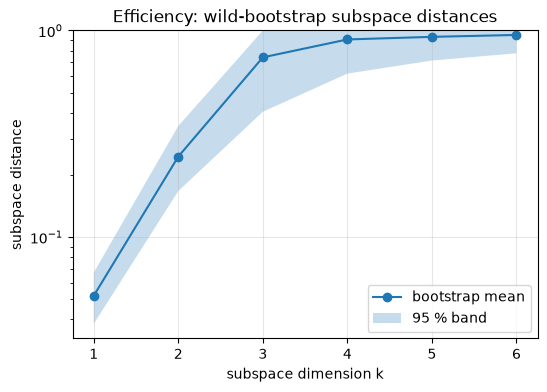

In [6]:
def dist_figure(q, title):
    d = res[q]['distb']
    k = np.arange(1, 7)
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.semilogy(k, d.mean(0)[:6], 'o-', label='bootstrap mean')
    ax.fill_between(k, *np.percentile(d[:, :6], [2.5, 97.5], axis=0), alpha=0.25, label='95 % band')
    ax.set_ylim(top=1); ax.set_xlabel('subspace dimension k'); ax.set_ylabel('subspace distance')
    ax.set_title(f'{title}: wild-bootstrap subspace distances'); ax.grid(True, alpha=0.3); ax.legend()
    plt.close(fig)
    print(f'{q}: mean subspace distance, k = 1..6:', np.array2string(d.mean(0)[:6], precision=3))
    return fig


fig = dist_figure('eta', 'Efficiency')
fig

The first direction is well determined (mean distance 0.052) and the 2-D subspace reasonably so (0.245); beyond $k = 2$ the distances exceed 0.7.

**Eigenvectors.** Bars: our first two eigenvectors, with 95 % wild-bootstrap intervals; crosses: the paper's Fig. 8(b), read by pixel measurement (to about ±0.01).

eta w1: LE 75 -0.604, LE 100 -0.542, TE 100 -0.356, LE 50 -0.300, TE 75 -0.267, LE 25 -0.148 ...; |w1 . paper w1| = 0.992; largest |difference| 0.047
    paper w1 components more than 0.02 (twice the reading error) outside our 95 % interval: dih 75 (paper -0.05, ours [-0.03, +0.01]), dih 100 (paper -0.02, ours [-0.08, -0.04]), swp 50 (paper -0.04, ours [-0.01, +0.03]), skw 0 (paper -0.02, ours [+0.00, +0.04])
eta w2: TE 100 -0.646, TE 75 -0.445, LE 50 +0.428, LE 75 +0.302, LE 25 +0.220, swp 50 +0.106 ...; |w2 . paper w2| = 0.907; largest |difference| 0.219
    paper w2 components more than 0.02 (twice the reading error) outside our 95 % interval: LE 25 (paper +0.07, ours [+0.12, +0.31]), swp 100 (paper +0.18, ours [-0.13, +0.07]), skw 50 (paper -0.11, ours [-0.09, +0.13])
eta: distance between the notebook and paper 2-D subspaces 0.419


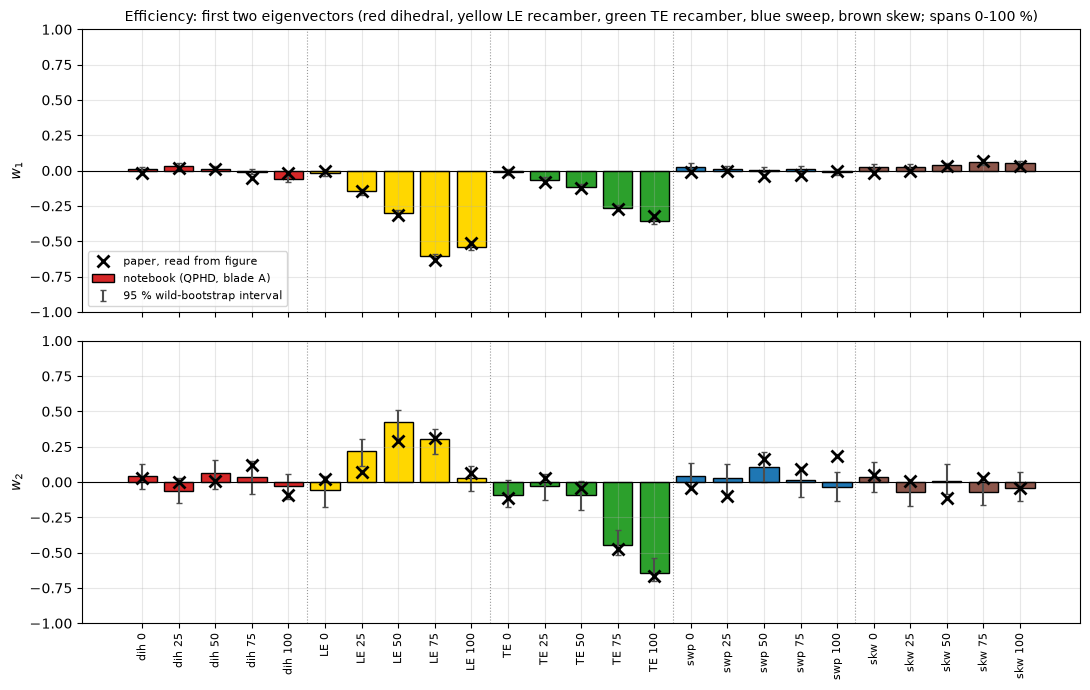

In [7]:
def vec_figure(q, title):
    r = res[q]; W = r['sub'].W; Wb = r['Wb']; pW = paper[q + '_W']
    colors = np.repeat(['C3', 'gold', 'C2', 'C0', 'C5'], 5)
    fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
    k = np.arange(1, m + 1)
    for i, ax in enumerate(axes):
        lo, hi = np.percentile(Wb[:, :, i], [2.5, 97.5], axis=0)
        ax.bar(k, W[:, i], color=colors, edgecolor='k', label='notebook (QPHD, blade A)')
        ax.errorbar(k, W[:, i], yerr=[W[:, i] - lo, hi - W[:, i]], fmt='none', ecolor='0.3', capsize=2,
                    label='95 % wild-bootstrap interval')
        ax.plot(k, pW[:, i], 'kx', ms=8, mew=2, label='paper, read from figure')
        ax.axhline(0, color='k', lw=0.8); ax.set_ylabel(f'$w_{i + 1}$'); ax.set_ylim(-1, 1); ax.grid(True, alpha=0.3)
        for x in (5.5, 10.5, 15.5, 20.5):
            ax.axvline(x, color='0.6', lw=0.8, ls=':')
    axes[0].legend(loc='lower left', fontsize=8)
    axes[0].set_title(f'{title}: first two eigenvectors (red dihedral, yellow LE recamber, green TE recamber, '
                      'blue sweep, brown skew; spans 0-100 %)', fontsize=10)
    axes[1].set_xticks(k); axes[1].set_xticklabels(labels, rotation=90, fontsize=8)
    fig.tight_layout(); plt.close(fig)
    for i in range(2):
        order = np.argsort(-np.abs(W[:, i]))[:6]
        print(f'{q} w{i + 1}: ' + ', '.join(f'{labels[j]} {W[j, i]:+.3f}' for j in order)
              + f' ...; |w{i + 1} . paper w{i + 1}| = {abs(W[:, i] @ pW[:, i]):.3f}; '
              f'largest |difference| {np.abs(W[:, i] - pW[:, i]).max():.3f}')
        lo, hi = np.percentile(Wb[:, :, i], [2.5, 97.5], axis=0)
        out = [j for j in range(m) if abs(pW[j, i] - np.clip(pW[j, i], lo[j], hi[j])) > 0.02]
        print(f'    paper w{i + 1} components more than 0.02 (twice the reading error) outside our 95 % interval: '
              + (', '.join(f'{labels[j]} (paper {pW[j, i]:+.2f}, ours [{lo[j]:+.2f}, {hi[j]:+.2f}])' for j in out) or 'none'))
    Pm = W[:, :2].T @ pW
    print(f'{q}: distance between the notebook and paper 2-D subspaces '
          f'{np.sqrt(max(0.0, 1 - np.linalg.svd(Pm, compute_uv=False).min()**2)):.3f}')
    return fig


fig = vec_figure('eta', 'Efficiency')
fig

The first eigenvector reproduces the paper's: $|\mathbf w_1\cdot\mathbf w_1^{\mathrm{paper}}| = 0.992$, and no component differs by more than 0.047. It is carried by LE recamber at 75 % (−0.604), 100 % (−0.542) and 50 % span (−0.300), and TE recamber at 100 % (−0.356) and 75 % (−0.267), all with the same sign: a combined recambering of the outer half of the blade (the paper's Fig. 10 shows the corresponding camberline and inlet-angle changes). Only four small components of the paper's $\mathbf w_1$ (dihedral at 75 and 100 %, sweep at 50 %, skew at 0 %, all of magnitude 0.05 or less) lie more than 0.02, twice the reading error, outside our 95 % intervals. The second eigenvector agrees less well, $|\mathbf w_2\cdot\mathbf w_2^{\mathrm{paper}}| = 0.907$: its main components, TE recamber at 100 % (−0.646) and 75 % (−0.445) against LE recamber at 50 % (+0.428) and 75 % (+0.302), have the paper's pattern, but some components differ by up to 0.219, and the distance between the two 2-D subspaces is 0.419. Three of the paper's components lie more than 0.02 outside our 95 % intervals: LE recamber at 25 % (paper +0.07, ours $[+0.12, +0.31]$), sweep at 100 % (+0.18 against $[-0.13, +0.07]$) and skew at 50 % (−0.11 against $[-0.09, +0.13]$). So the difference in $\mathbf w_2$ is more than the resampling spread of our fit; it may come from the different designs (500 runs in the paper, 548 here) or the different quadratic fits.

**Sufficient summary plots.** Efficiency against $y_1$ (left) and over $(y_1, y_2)$ (right), with the signs of the paper.

y1 in [-1.80, 1.44], y2 in [-1.33, 1.41]
1-D cubic in y1: peak +0.159 at y1 = 0.62; value at y1 = -1.5: -0.669, at y1 = +1.4: -0.030
corr(y1, eta) = 0.861; highest eta 0.2589 at (y1, y2) = (0.64, -1.33); lowest -0.7936 at y1 = -1.80


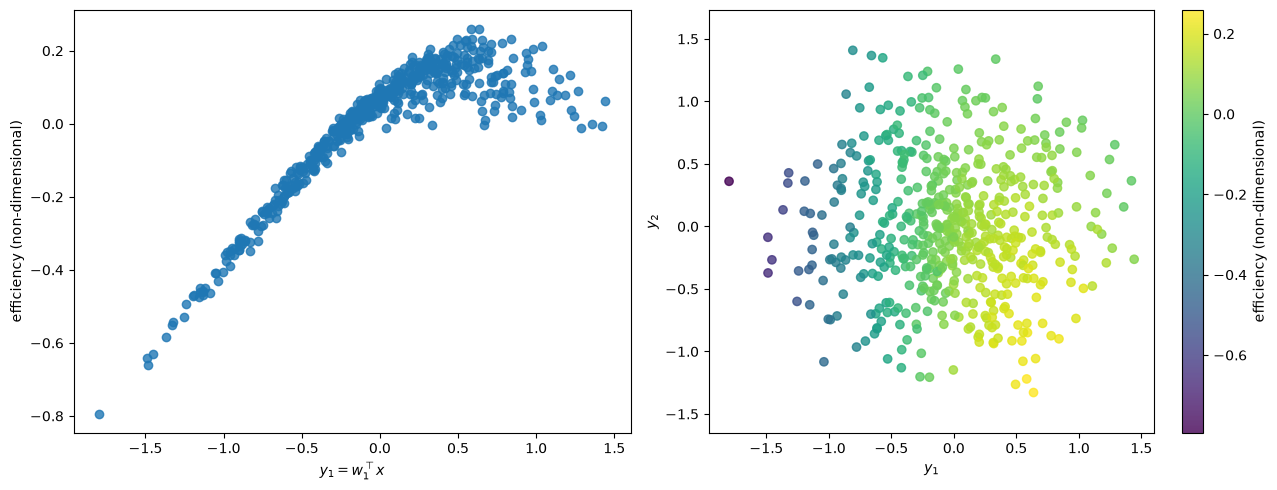

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ac.plotting.plot_sufficient_summary(ac.with_dimension(res['eta']['sub'], 1), X=XA, f=etaA, dims=1,
                                    qoi_label='efficiency (non-dimensional)', ax=axes[0])
ac.plotting.plot_sufficient_summary(ac.with_dimension(res['eta']['sub'], 2), X=XA, f=etaA, dims=2,
                                    qoi_label='efficiency (non-dimensional)', ax=axes[1])
fig.tight_layout(); plt.close(fig)
YA_eta = space.to_normalized(XA) @ res['eta']['sub'].W[:, :2]
i_max = np.argmax(etaA)
print(f'y1 in [{YA_eta[:, 0].min():.2f}, {YA_eta[:, 0].max():.2f}], y2 in [{YA_eta[:, 1].min():.2f}, {YA_eta[:, 1].max():.2f}]')
c1 = ac.fit_surrogate(X=XA, f=etaA, subspace=ac.with_dimension(res['eta']['sub'], 1), kind='poly', degree=3)
yy = np.linspace(YA_eta[:, 0].min(), YA_eta[:, 0].max(), 401)
cy = c1.evaluate(yy[:, None])
print(f'1-D cubic in y1: peak {cy.max():+.3f} at y1 = {yy[np.argmax(cy)]:.2f}; value at y1 = -1.5: {c1.evaluate(np.array([[-1.5]]))[0]:+.3f}, '
      f'at y1 = +1.4: {c1.evaluate(np.array([[1.4]]))[0]:+.3f}')
print(f'corr(y1, eta) = {np.corrcoef(YA_eta[:, 0], etaA)[0, 1]:.3f}; highest eta {etaA[i_max]:.4f} at '
      f'(y1, y2) = ({YA_eta[i_max, 0]:.2f}, {YA_eta[i_max, 1]:.2f}); lowest {etaA.min():.4f} at y1 = {YA_eta[np.argmin(etaA), 0]:.2f}')
fig

Efficiency rises steeply along $y_1$ from the lowest value, −0.7936 at $y_1 = -1.80$, to a ridge and then falls off more gently ($\mathrm{corr}(y_1, \eta) = 0.861$): a cubic in $y_1$ peaks at +0.159 at $y_1 = 0.62$ and is −0.669 at $y_1 = -1.5$ but −0.030 at $y_1 = +1.4$. The fall beyond the ridge is spread out along $y_2$: the highest efficiency, 0.2589, is at $(y_1, y_2) = (0.64, -1.33)$. This is the shape of the paper's Fig. 8(a), a ridge with a steeper low-efficiency side.

**Performance map.** As in the paper's Figs. 9(a) and 17, we interpolate the 548 efficiencies piecewise linearly over the triangulated active coordinates and draw the zonotope $\mathcal Y = \mathbf W_1^T[-1, 1]^{25}$, the image of the design space, with the paper's vector $\mathbf v = (0.4, -1.6)$ from the research blade at the origin. The cell also evaluates a quadratic in $(y_1, y_2)$ along $\mathbf v$.

2-D quadratic in the efficiency active variables along v (t = 0, 0.2, ..., 1): +0.065, +0.099, +0.131, +0.159, +0.185, +0.208
designs within 0.25 of the line through v: 216, mean eta +0.067 (all designs +0.000); of the top 10 % of eta, 100% have y2 < 0 and 100% have y1 > 0
zonotope: 50 vertices; y1 in [-2.80, 2.80], y2 in [-3.02, 3.02]


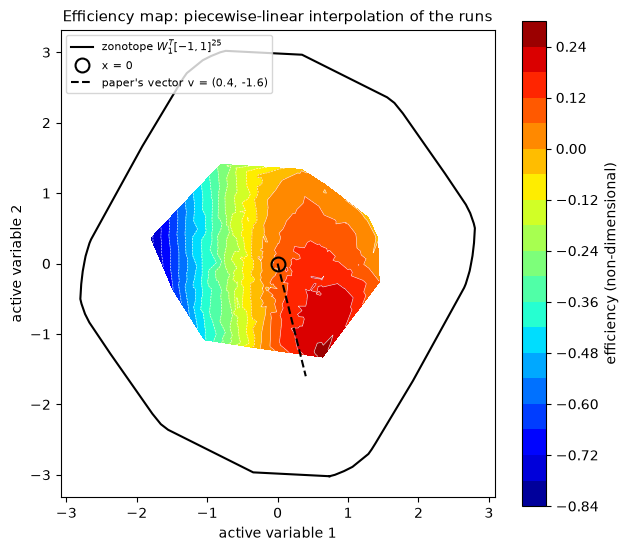

In [9]:
zono = {}


def perf_map(Y, f, sub2, title, corridor=None, levels=20, name=''):
    dom = ac.active_domain(sub2)
    V = np.vstack([dom.vertices, dom.vertices[:1]])
    tri = mtri.Triangulation(Y[:, 0], Y[:, 1])
    fig, ax = plt.subplots(figsize=(7, 6.3))
    cs = ax.tricontourf(tri, f, levels=levels, cmap='jet')
    ax.tricontour(tri, f, levels=levels, colors='w', linewidths=0.4)
    ax.plot(V[:, 0], V[:, 1], 'k-', lw=1.5, label='zonotope $W_1^T[-1,1]^{25}$')
    ax.plot(0, 0, 'ko', mfc='none', ms=10, mew=1.5, label='x = 0')
    if corridor is not None:
        ax.plot([0, corridor[0]], [0, corridor[1]], 'k--', lw=1.5, label='paper\'s vector v = (0.4, -1.6)')
    fig.colorbar(cs, ax=ax, label=title)
    ax.set_aspect('equal'); ax.set_xlabel('active variable 1'); ax.set_ylabel('active variable 2')
    ax.legend(loc='upper left', fontsize=8); ax.set_title(f'{name}: piecewise-linear interpolation of the runs', fontsize=11)
    plt.close(fig)
    zono[title] = (dom.vertices[:, 0].max(), dom.vertices[:, 1].max())
    print(f'zonotope: {len(dom.vertices)} vertices; y1 in [{dom.vertices[:, 0].min():.2f}, {dom.vertices[:, 0].max():.2f}], '
          f'y2 in [{dom.vertices[:, 1].min():.2f}, {dom.vertices[:, 1].max():.2f}]')
    return fig


sub2_eta = ac.with_dimension(res['eta']['sub'], 2)
q2_eta = ac.fit_surrogate(X=XA, f=etaA, subspace=sub2_eta, kind='poly', degree=2)
v = np.array([0.4, -1.6])
t = np.linspace(0, 1, 6)
along = q2_eta.evaluate(np.outer(t, v))
print('2-D quadratic in the efficiency active variables along v (t = 0, 0.2, ..., 1): '
      + ', '.join(f'{a:+.3f}' for a in along))
band = np.abs((YA_eta - np.outer(YA_eta @ v / (v @ v), v)) @ np.array([v[1], -v[0]]) / np.linalg.norm(v)) < 0.25
top = etaA >= np.quantile(etaA, 0.9)
print(f'designs within 0.25 of the line through v: {band.sum()}, mean eta {etaA[band].mean():+.3f} '
      f'(all designs {etaA.mean():+.3f}); of the top 10 % of eta, {np.mean(YA_eta[top, 1] < 0):.0%} have y2 < 0 '
      f'and {np.mean(YA_eta[top, 0] > 0):.0%} have y1 > 0')
fig = perf_map(YA_eta, etaA, sub2_eta, 'efficiency (non-dimensional)', corridor=v, name='Efficiency map')
fig

The map reproduces the paper's Figs. 9(a) and 17(a): low efficiency on the left, a high-efficiency region right of and below the origin, and the highest values along the paper's corridor $\mathbf v$. All of the top 10 % of designs by efficiency have $y_1 > 0$ and $y_2 < 0$; along $\mathbf v$ the 2-D quadratic rises from +0.065 at the origin to +0.208 at $\mathbf v$ itself; and the 216 designs within 0.25 of the line through $\mathbf v$ average +0.067 against 0 for all designs. The zonotope spans $[-2.80, 2.80]\times[-3.02, 3.02]$, close to the paper's (about $[-2.9, 2.9]\times[-3.2, 3.2]$, Fig. 17). The data cover only its centre, as in the paper, whose Sec. 4 adds CFD runs outside the sampled region; those runs are not in the archive. The paper's corridor end point $\mathbf v$ is itself just outside our data (smallest $y_2$ of a run: −1.33).

### Results: cruise pressure ratio

The same steps for the pressure ratio; the paper's values are from Figs. 7(b) and 13(b).

pr: 2.5-97.5 % replicate range lambda_1 [7.99e-05, 8.2e-05]; lambda_2 [1.96e-06, 2.65e-06]; lambda_3 [1.58e-07, 3.43e-07]
pr: bootstrap lambda_1/lambda_2 2.5-97.5 %: [30.5, 41.4]
pr: paper Fig. 7 ratios p1/p2 = 5.20, p2/p3 = 4.67; their squares 27.0, 21.8
pr: rms log10 difference from Fig. 7 over 25 values: lambda/lambda_1 1.941, sqrt(lambda/lambda_1) 0.072; with the printed Eq. 11, sqrt 0.340; paper first value / sqrt(lambda_1) = 3.97
pr: estimate below the 2.5 % replicate percentile for 19 of 25 eigenvalues (smallest such k = 3: 1.21e-07 against [1.58e-07, 3.43e-07]); estimate / replicate mean, k = 1-4: 0.999, 0.977, 0.518, 0.547
pr: contour map with 0.005 spacing, 20-21 fill levels: paper range about 0.095-0.105; archive range 0.02692; ratio 3.53-3.90


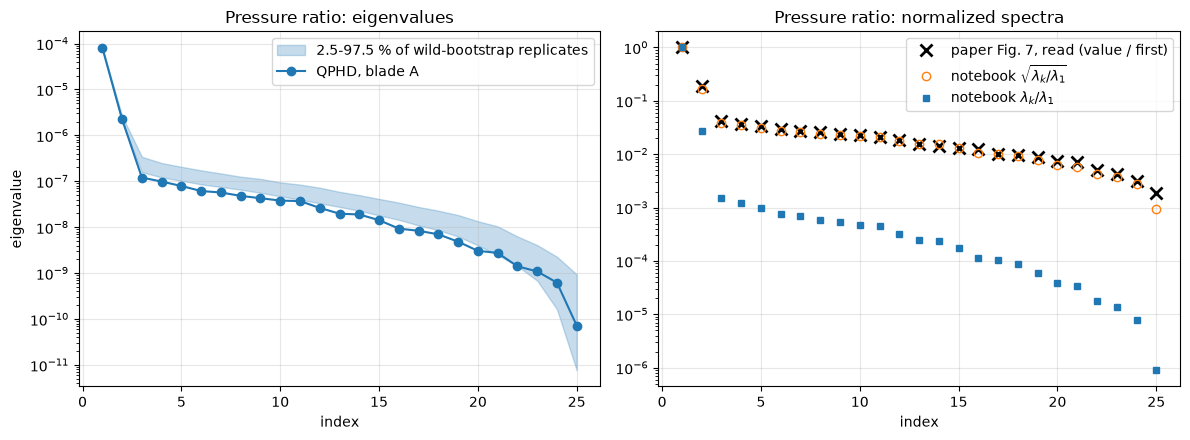

In [10]:
fig = eig_figure('pr', 'Pressure ratio')
fig

For pressure ratio the replicate range is narrow: $\lambda_1 \in [7.99, 8.20]\times10^{-5}$, $\lambda_2 \in [1.96, 2.65]\times10^{-6}$ and $\lambda_1/\lambda_2 \in [30.5, 41.4]$. As for efficiency, from $k = 3$ on it lies above the estimates (19 of 25; $\lambda_3 = 1.21\times10^{-7}$ against $[1.58, 3.43]\times10^{-7}$). Again Fig. 7(b) matches the square roots of our eigenvalues: the root-mean-square $\log_{10}$ difference of the normalized spectra is 0.072, against 1.941 for the eigenvalues themselves and 0.340 for the square roots under the printed Eq. 11, and the paper's ratios 5.20 and 4.67 square to 27.0 and 21.8, against our 36.1 and 18.55. The paper's first value is 3.97 times our $\sqrt{\lambda_1}$. Fig. 16(a), with 0.005 between contour lines (caption, p. 7) and about 20–21 fill levels, spans about 0.095–0.105 in pressure ratio, 3.53–3.90 times the archive's range of 0.02692, which agrees. So the archive's pressure ratio looks like the paper's divided by roughly 4, and its efficiency by roughly 3 (2.66–3.42 from Fig. 9(a), 2.96 from Fig. 7); whether the two factors really differ cannot be settled from figure readings.

pr: mean subspace distance, k = 1..6: [0.016 0.113 0.761 0.902 0.894 0.941]


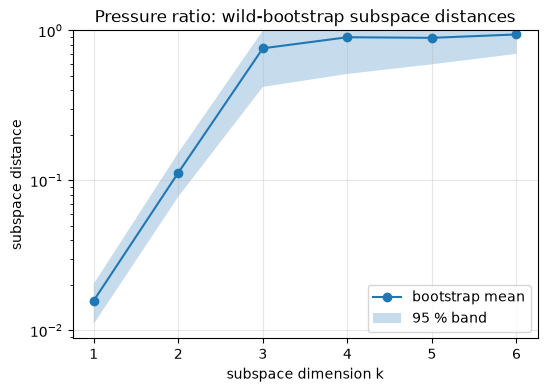

In [11]:
fig = dist_figure('pr', 'Pressure ratio')
fig

The mean subspace distances are 0.016 for $k = 1$ and 0.113 for $k = 2$, then 0.761: both of the paper's directions are well determined.

pr w1: TE 75 -0.631, TE 100 -0.618, TE 50 -0.354, TE 25 -0.208, LE 100 +0.109, skw 100 -0.100 ...; |w1 . paper w1| = 0.988; largest |difference| 0.094
    paper w1 components more than 0.02 (twice the reading error) outside our 95 % interval: LE 50 (paper +0.09, ours [+0.04, +0.05]), LE 75 (paper +0.19, ours [+0.09, +0.11]), LE 100 (paper +0.20, ours [+0.10, +0.12]), TE 100 (paper -0.57, ours [-0.62, -0.61])
pr w2: LE 75 +0.655, LE 100 +0.626, LE 50 +0.262, TE 100 +0.199, LE 25 +0.150, TE 75 +0.099 ...; |w2 . paper w2| = 0.971; largest |difference| 0.103
    paper w2 components more than 0.02 (twice the reading error) outside our 95 % interval: LE 100 (paper +0.54, ours [+0.58, +0.66]), TE 50 (paper +0.03, ours [-0.07, +0.01]), TE 75 (paper +0.20, ours [+0.06, +0.13]), TE 100 (paper +0.27, ours [+0.16, +0.24]), swp 0 (paper +0.04, ours [-0.11, -0.00])
pr: distance between the notebook and paper 2-D subspaces 0.196


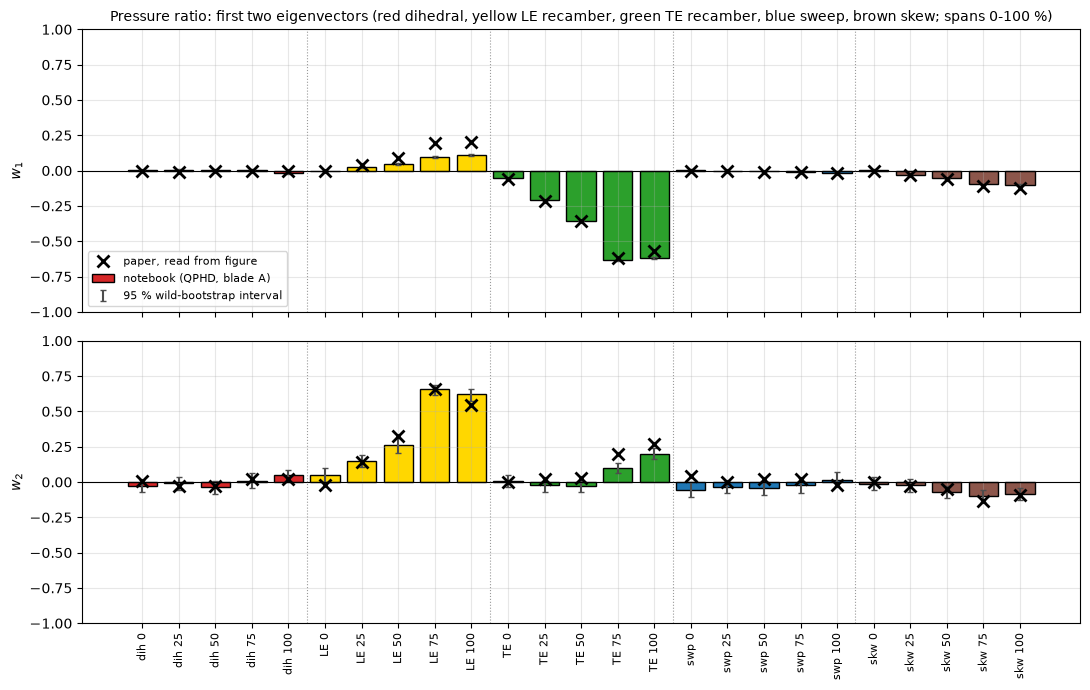

In [12]:
fig = vec_figure('pr', 'Pressure ratio')
fig

The first eigenvector is TE recamber at 75 % (−0.631), 100 % (−0.618), 50 % (−0.354) and 25 % (−0.208) span, with smaller LE recamber (+0.109 at 100 %) and skew (−0.100 at 100 %) components: more trailing-edge camber, more turning, more pressure rise, as the paper concludes from Figs. 14 and 15. It matches the paper's, $|\mathbf w_1\cdot\mathbf w_1^{\mathrm{paper}}| = 0.988$, though the paper's LE recamber components at 75 and 100 % span (+0.19, +0.20) are about twice ours (95 % intervals $[+0.09, +0.11]$ and $[+0.10, +0.12]$), and its TE recamber at 100 % is −0.57 against our −0.62. The second eigenvector, mostly LE recamber at 75 % (+0.655) and 100 % (+0.626), also matches ($|\mathbf w_2\cdot\mathbf w_2^{\mathrm{paper}}| = 0.971$; distance between the 2-D subspaces 0.196).

**Sufficient summary plots.** Pressure ratio against $y_1$ (left) and over $(y_1, y_2)$ (right):

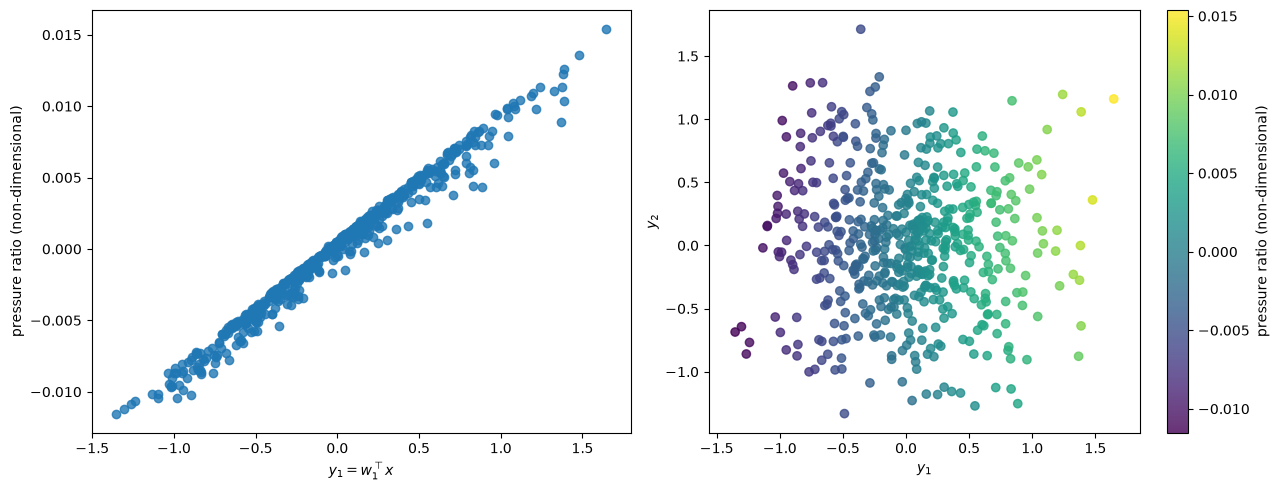

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ac.plotting.plot_sufficient_summary(ac.with_dimension(res['pr']['sub'], 1), X=XA, f=prA, dims=1,
                                    qoi_label='pressure ratio (non-dimensional)', ax=axes[0])
ac.plotting.plot_sufficient_summary(ac.with_dimension(res['pr']['sub'], 2), X=XA, f=prA, dims=2,
                                    qoi_label='pressure ratio (non-dimensional)', ax=axes[1])
fig.tight_layout(); plt.close(fig)
fig

Pressure ratio is close to linear in $y_1$ (the next cell prints $\mathrm{corr}(y_1, \mathrm{PR}) = 0.9900$), as in the paper's Fig. 13(a); the spread at fixed $y_1$ is what the second variable picks up.

**Performance maps** (the paper's Fig. 16). The cell draws (a) the piecewise-linear interpolation of the runs and (b) a quadratic in $(y_1, y_2)$ fitted to them, on a square grid as in Fig. 16(b).

y1 in [-1.35, 1.64], y2 in [-1.33, 1.71]; corr(y1, PR) = 0.9900
LOO R^2 of quadratics in the PR active variables: 1-D 0.9807, 2-D 0.9983
zonotope: 50 vertices; y1 in [-2.52, 2.52], y2 in [-2.69, 2.69]
quadratic at (0, 1.5), (0, -1.5), (0, 0): -0.00181, -0.00230, +0.00046; change per unit y1 near 0: +0.00893


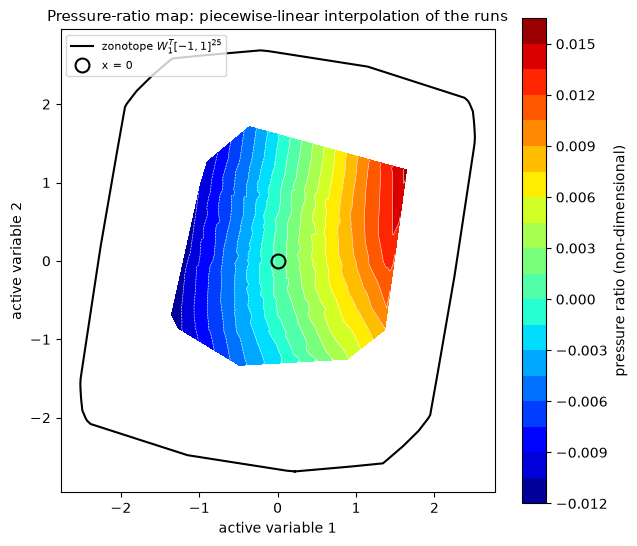

In [14]:
sub1_pr, sub2_pr = ac.with_dimension(res['pr']['sub'], 1), ac.with_dimension(res['pr']['sub'], 2)
YA_pr = space.to_normalized(XA) @ res['pr']['sub'].W[:, :2]
q2_pr = ac.fit_surrogate(X=XA, f=prA, subspace=sub2_pr, kind='poly', degree=2)
q1_pr = ac.fit_surrogate(X=XA, f=prA, subspace=sub1_pr, kind='poly', degree=2)
print(f'y1 in [{YA_pr[:, 0].min():.2f}, {YA_pr[:, 0].max():.2f}], y2 in [{YA_pr[:, 1].min():.2f}, {YA_pr[:, 1].max():.2f}]; '
      f'corr(y1, PR) = {np.corrcoef(YA_pr[:, 0], prA)[0, 1]:.4f}')
print(f'LOO R^2 of quadratics in the PR active variables: 1-D {q1_pr.loo_r_squared:.4f}, 2-D {q2_pr.loo_r_squared:.4f}')
fig = perf_map(YA_pr, prA, sub2_pr, 'pressure ratio (non-dimensional)', name='Pressure-ratio map')
g1, g2 = np.meshgrid(np.linspace(-1.8, 1.8, 121), np.linspace(-1.8, 1.8, 121))
G = q2_pr.evaluate(np.column_stack([g1.ravel(), g2.ravel()])).reshape(g1.shape)
fig_q, ax = plt.subplots(figsize=(6.5, 5.5))
cs = ax.contourf(g1, g2, G, levels=20, cmap='jet'); ax.contour(g1, g2, G, levels=20, colors='w', linewidths=0.4)
ax.plot(0, 0, 'ko', mfc='none', ms=10, mew=1.5); fig_q.colorbar(cs, ax=ax, label='pressure ratio (non-dimensional)')
ax.set_aspect('equal'); ax.set_xlabel('PR active variable 1'); ax.set_ylabel('PR active variable 2')
ax.set_title('Pressure ratio: 2-D quadratic response (cf. Fig. 16(b))'); plt.close(fig_q)
# the bend of the contours: the y2 dependence of the quadratic at fixed y1
dG = q2_pr.evaluate(np.array([[0.0, 1.5], [0.0, -1.5], [0.0, 0.0]]))
print(f'quadratic at (0, 1.5), (0, -1.5), (0, 0): ' + ', '.join(f'{d:+.5f}' for d in dG)
      + f'; change per unit y1 near 0: {q2_pr.evaluate(np.array([[0.5, 0.0]]))[0] - q2_pr.evaluate(np.array([[-0.5, 0.0]]))[0]:+.5f}')
fig

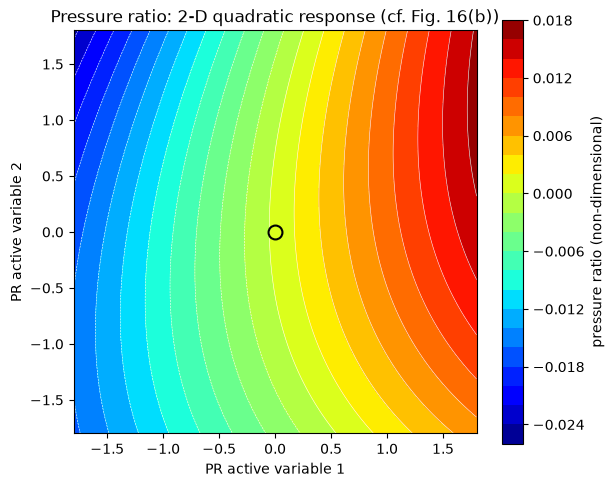

In [15]:
fig = fig_q
fig

The pressure ratio is almost a function of $y_1$ alone: $\mathrm{corr}(y_1, \mathrm{PR}) = 0.9900$, and the LOO $R^2$ of a quadratic is 0.9807 in $y_1$ and 0.9983 in $(y_1, y_2)$. The quadratic response has the paper's chevron-shaped contours (Fig. 16(b)): at $y_1 = 0$ it is +0.00046 at $y_2 = 0$ but −0.00181 and −0.00230 at $y_2 = \pm1.5$, so pressure ratio falls on both sides of $y_2 = 0$, while it rises by 0.00893 per unit of $y_1$. The data occupy $y_1 \in [-1.35, 1.64]$, $y_2 \in [-1.33, 1.71]$; the paper's Fig. 16(a) covers about $[-1.7, 1.4]\times[-1.6, 1.3]$, a mirror image in $y_1$ of our range (the signs are fixed by the paper's bar charts and PR increases with $y_1$ in both), which we take as a sign that the paper's 500 designs differ from the archive's 548.

### Pressure ratio on the efficiency map

The paper's Sec. 4.4 (Figs. 19–20) draws pressure ratio on the efficiency active variables. For each point of a grid in the efficiency plane it finds a 25-D design by a linear program (an inverse map) and evaluates the pressure-ratio response surface there. We do the same with the library's `inverse_map` (hit-and-run on the fiber $\{\mathbf x \in [-1,1]^{25} : \mathbf W_1^T\mathbf x = \mathbf y\}$), 40 draws per grid point inside the hull of the runs, and the 2-D pressure-ratio quadratic above; we plot the mean over the fiber, since a single draw is arbitrary.

164 grid points x 40 inverse-map draws in 1.0 s; max |W1^T x - y| = 6.7e-16
PR on the efficiency plane: fiber mean from -0.0127 to +0.0121; median s.d. along a fiber 0.0023 (s.d. of PR over the runs 0.0049); corr(fiber mean, y1) = +0.33, corr(fiber mean, y2) = +0.87
v = (0.4, -1.6) inside the hull of the runs: False; smallest y2 of a run -1.33
along v (t = 0, 0.2, ..., 1): efficiency (2-D quadratic) +0.065, +0.099, +0.131, +0.159, +0.185, +0.208
                              PR fiber mean (50 draws)      -0.0006, -0.0026, -0.0035, -0.0051, -0.0092, -0.0073; fiber s.d. 0.0022, 0.0041, 0.0024, 0.0024, 0.0022, 0.0023
through the Fig. 7 factors (2.96, 3.97): efficiency gain along v 0.143 x 2.96 = 0.42 %; PR fiber-mean drop at t = 0.8, 1: 0.0086, 0.0067 x 3.97 = 0.034, 0.027
angle between the efficiency and PR first eigenvectors: 72.9 deg


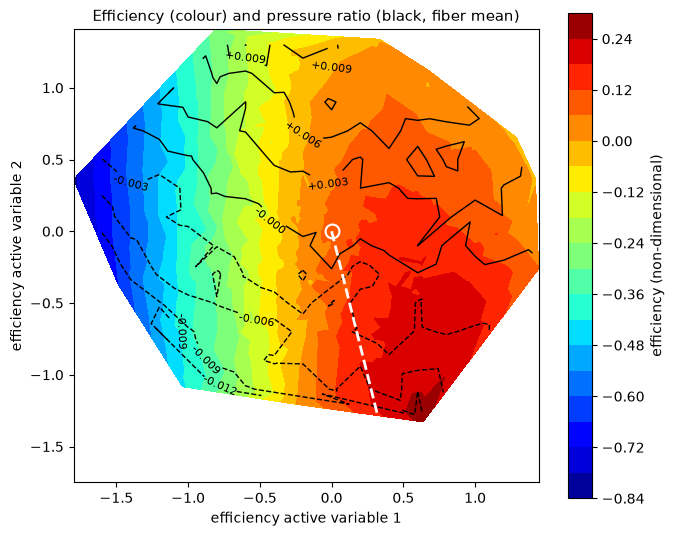

In [16]:
from scipy.spatial import Delaunay
# grid on the efficiency plane, inside the convex hull of the runs' efficiency active coordinates
hull = Delaunay(YA_eta)
g1, g2 = np.meshgrid(np.arange(-1.8, 1.51, 0.2), np.arange(-1.3, 1.41, 0.2))
G = np.column_stack([g1.ravel(), g2.ravel()])
G = G[hull.find_simplex(G) >= 0]
t0 = time.perf_counter()
inv = ac.inverse_map(sub2_eta, Y=G, n_draws=40, rng=SEED)          # 40 cube points on each fiber
pr_inv = q2_pr.evaluate(inv.X @ res['pr']['sub'].W[:, :2]).reshape(len(G), 40)   # 2-D PR quadratic (Fig. 16(b))
pr_mean, pr_sd = pr_inv.mean(1), pr_inv.std(1, ddof=1)
eta_grid = q2_eta.evaluate(G)
print(f'{len(G)} grid points x 40 inverse-map draws in {time.perf_counter() - t0:.1f} s; '
      f'max |W1^T x - y| = {np.abs(inv.X @ sub2_eta.W1 - G[inv.index]).max():.1e}')
print(f'PR on the efficiency plane: fiber mean from {pr_mean.min():+.4f} to {pr_mean.max():+.4f}; '
      f'median s.d. along a fiber {np.median(pr_sd):.4f} (s.d. of PR over the runs {prA.std(ddof=1):.4f}); '
      f'corr(fiber mean, y1) = {np.corrcoef(G[:, 0], pr_mean)[0, 1]:+.2f}, corr(fiber mean, y2) = {np.corrcoef(G[:, 1], pr_mean)[0, 1]:+.2f}')
print(f'v = (0.4, -1.6) inside the hull of the runs: {hull.find_simplex(v[None, :])[0] >= 0}; '
      f'smallest y2 of a run {YA_eta[:, 1].min():.2f}')
pts = np.outer(np.linspace(0, 1, 6), v)
inv_v = ac.inverse_map(sub2_eta, Y=pts, n_draws=50, rng=SEED)
pr_v = q2_pr.evaluate(inv_v.X @ res['pr']['sub'].W[:, :2]).reshape(len(pts), 50)
print('along v (t = 0, 0.2, ..., 1): efficiency (2-D quadratic) ' + ', '.join(f'{a:+.3f}' for a in q2_eta.evaluate(pts)))
print('                              PR fiber mean (50 draws)      ' + ', '.join(f'{a:+.4f}' for a in pr_v.mean(1))
      + '; fiber s.d. ' + ', '.join(f'{a:.4f}' for a in pr_v.std(1, ddof=1)))
fe, fp = res['eta']['fac7'], res['pr']['fac7']
gain = q2_eta.evaluate(pts)[-1] - q2_eta.evaluate(pts)[0]
drop = pr_v.mean(1)[0] - pr_v.mean(1)[[4, 5]]
print(f'through the Fig. 7 factors ({fe:.2f}, {fp:.2f}): efficiency gain along v {gain:.3f} x {fe:.2f} = {gain * fe:.2f} %; '
      f'PR fiber-mean drop at t = 0.8, 1: {drop[0]:.4f}, {drop[1]:.4f} x {fp:.2f} = {drop[0] * fp:.3f}, {drop[1] * fp:.3f}')
print(f'angle between the efficiency and PR first eigenvectors: '
      f'{np.degrees(np.arccos(abs(res["eta"]["sub"].W[:, 0] @ res["pr"]["sub"].W[:, 0]))):.1f} deg')

tri = mtri.Triangulation(YA_eta[:, 0], YA_eta[:, 1])
fig, ax = plt.subplots(figsize=(7.5, 6.3))
cs = ax.tricontourf(tri, etaA, levels=20, cmap='jet')
tg = mtri.Triangulation(G[:, 0], G[:, 1])
cl = ax.tricontour(tg, pr_mean, levels=np.arange(-0.012, 0.0121, 0.003), colors='k', linewidths=1.0)
ax.clabel(cl, fmt='%+.3f', fontsize=8)
ax.plot([0, v[0]], [0, v[1]], 'w--', lw=2)
ax.plot(0, 0, 'wo', mfc='none', ms=10, mew=1.5)
fig.colorbar(cs, ax=ax, label='efficiency (non-dimensional)')
ax.set_aspect('equal'); ax.set_xlabel('efficiency active variable 1'); ax.set_ylabel('efficiency active variable 2')
ax.set_title('Efficiency (colour) and pressure ratio (black, fiber mean)', fontsize=11)
plt.close(fig)
fig

On the efficiency plane, pressure ratio increases mainly with $y_2$ (correlation of the fiber mean with $y_2$: +0.87, with $y_1$: +0.33), from −0.0127 to +0.0121 over the grid; its median standard deviation along a fiber, 0.0023, is about half the spread of pressure ratio over the runs (0.0049), so the efficiency variables only partly determine it. Along the corridor $\mathbf v$ efficiency rises (+0.065 to +0.208) while the fiber-mean pressure ratio falls from −0.0006 at the origin to −0.0092 and −0.0073 at the last two points ($t = 0.8, 1$; the second is outside the data). This is the paper's trade-off (Sec. 4.4, Fig. 20(b)): more efficient designs along $\mathbf v$ have a lower pressure ratio. The paper's numbers for it (a 0.4 % efficiency gain for a 0.041 drop in pressure ratio, pp. 7–8) come from new CFD runs beyond the sampled region and are in the paper's units, so they cannot be checked directly. Through the factors inferred from Fig. 7, our efficiency gain along $\mathbf v$ (0.143) is 0.42 % and our pressure-ratio drop at $t = 0.8$ and 1 (0.0086, 0.0067) is 0.034 and 0.027: the same order as the paper's, which supports the inferred scaling but rests on it. The first eigenvectors of the two quantities are 72.9° apart.

### Cross-checks

**Local linear gradients.** A second estimator that makes no global assumption: at each design a linear least-squares fit to its nearest neighbours (library default $p = \lfloor 1.7m\rfloor = 42$) gives a gradient, and $\hat{\mathbf C} = \frac1M\sum_i\nabla f_i\nabla f_i^T$ follows (`estimator="as"`, 500 bootstrap replicates, which are valid here because they resample gradients). We average only over the 458 outer designs, which sample $[-1, 1]^{25}$ uniformly, and take neighbours from all 548. In 25 dimensions 42 neighbours are far apart, so these gradients are regional averages that damp curvature. We also run the paper's linear recipe (Sec. 3.1.1: OLS on all 25 inputs, $\mathbf w = \mathbf u/\lVert\mathbf u\rVert$).

In [17]:
outer = np.flatnonzero(~inner)
for q, f in [('eta', etaA), ('pr', prA)]:
    t0 = time.perf_counter()
    gl = ac.local_linear_gradients(X=XA, f=f, space=space, centers=outer)   # neighbours from all 548 runs
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        sll = ac.active_subspace(space=space, grads=gl, nboot=NBOOT, bootstrap_vectors=2, rng=SEED)
    sll = ac.orient(sll, by='reference', reference=res[q]['sub'], columns=2)
    res[q]['ll'] = sll
    W, L = res[q]['sub'].W, sll.W
    lam = sll.eigenvalues
    print(f'{q}: local linear gradients at the {len(outer)} outer designs (p = {int(np.floor(1.7 * m))} neighbours) '
          f'+ {NBOOT} bootstrap replicates, {time.perf_counter() - t0:.1f} s; warnings: '
          + ('; '.join(sorted({type(w.message).__name__ for w in caught})) or 'none'))
    print(f'    eigenvalues 1-4 {np.array2string(lam[:4], precision=3)}; lambda_1/lambda_2 = {lam[0] / lam[1]:.1f}, '
          f'lambda_2/lambda_3 = {lam[1] / lam[2]:.2f}; n = {sll.n}')
    print(f'    |w1(LL) . w1(QPHD)| = {abs(L[:, 0] @ W[:, 0]):.3f}, |w2(LL) . w2(QPHD)| = {abs(L[:, 1] @ W[:, 1]):.3f}; '
          f'|w1(LL) . paper w1| = {abs(L[:, 0] @ paper[q + "_W"][:, 0]):.3f}; '
          f'bootstrap mean distance k = 1, 2: {sll.bootstrap_distances.mean(0)[0]:.3f}, {sll.bootstrap_distances.mean(0)[1]:.3f}')
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        sols = ac.active_subspace(space=space, X=XA, f=f, estimator='ols')
    lin = ac.fit_surrogate(X=XA, f=f, space=space, subspace=None, kind='poly', degree=1)
    print(f'    linear recipe (Sec. 3.1.1, OLS on all 548 runs): |w . w1(QPHD)| = {abs(sols.W[:, 0] @ W[:, 0]):.3f}; '
          f'LOO R^2 of the 25-input linear fit {lin.loo_r_squared:.3f}')

eta: local linear gradients at the 458 outer designs (p = 42 neighbours) + 500 bootstrap replicates, 1.2 s; warnings: AccuracyWarning
    eigenvalues 1-4 [0.094 0.002 0.002 0.002]; lambda_1/lambda_2 = 39.8, lambda_2/lambda_3 = 1.23; n = 1
    |w1(LL) . w1(QPHD)| = 0.989, |w2(LL) . w2(QPHD)| = 0.602; |w1(LL) . paper w1| = 0.987; bootstrap mean distance k = 1, 2: 0.021, 0.421
    linear recipe (Sec. 3.1.1, OLS on all 548 runs): |w . w1(QPHD)| = 0.978; LOO R^2 of the 25-input linear fit 0.743


pr: local linear gradients at the 458 outer designs (p = 42 neighbours) + 500 bootstrap replicates, 1.1 s; warnings: none
    eigenvalues 1-4 [8.436e-05 2.254e-07 1.357e-07 1.165e-07]; lambda_1/lambda_2 = 374.2, lambda_2/lambda_3 = 1.66; n = 1
    |w1(LL) . w1(QPHD)| = 0.999, |w2(LL) . w2(QPHD)| = 0.838; |w1(LL) . paper w1| = 0.983; bootstrap mean distance k = 1, 2: 0.006, 0.212
    linear recipe (Sec. 3.1.1, OLS on all 548 runs): |w . w1(QPHD)| = 1.000; LOO R^2 of the 25-input linear fit 0.979


Local linear gradients find the same first directions: $|\mathbf w_1^{\mathrm{LL}}\cdot\mathbf w_1^{\mathrm{QPHD}}| = 0.989$ for efficiency and 0.999 for pressure ratio (0.987 and 0.983 against the paper). Their second directions agree less (0.602 and 0.838), and their bootstrap distances for $k = 2$ (0.421 and 0.212) show that they determine the second direction poorly, as their small second gaps (1.23 and 1.66) say; for efficiency the library warns that the bootstrap replicates of $\mathbf w_2$ are poorly aligned. Their first gaps are larger (39.8 and 374.2) because the regional fits smooth away curvature. The paper's linear recipe gives $|\mathbf w\cdot\mathbf w_1| = 0.978$ for efficiency and 1.000 for pressure ratio, but a linear model explains efficiency poorly (LOO $R^2 = 0.743$, against 0.979 for pressure ratio), which is why the paper moved to the quadratic (its Fig. 6).

### Surrogates

Polynomials in the active variables, with LOO $R^2$, against the 25-input quadratic (351 coefficients).

eta: LOO R^2 1-D degree 2: 0.9470; 1-D degree 3: 0.9551; 2-D degree 2: 0.9843; 2-D degree 3: 0.9894; 25-D quadratic: 0.9423
pr: LOO R^2 1-D degree 2: 0.9807; 1-D degree 3: 0.9805; 2-D degree 2: 0.9983; 2-D degree 3: 0.9990; 25-D quadratic: 0.9937


eta: 10-fold CV R^2, subspace re-estimated in each fold: 1-D degree 2: 0.9423; 2-D degree 2: 0.9769; 2-D degree 3: 0.9843; 25-D quadratic: 0.9229


pr: 10-fold CV R^2, subspace re-estimated in each fold: 1-D degree 2: 0.9801; 2-D degree 2: 0.9975; 2-D degree 3: 0.9986; 25-D quadratic: 0.9917


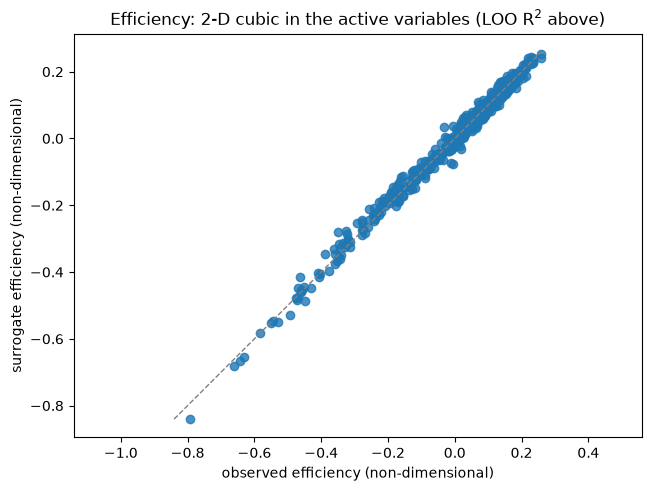

In [18]:
for q, f, sub in [('eta', etaA, res['eta']['sub']), ('pr', prA, res['pr']['sub'])]:
    out = []
    for n_, deg in [(1, 2), (1, 3), (2, 2), (2, 3)]:
        s = ac.fit_surrogate(X=XA, f=f, subspace=ac.with_dimension(sub, n_), kind='poly', degree=deg)
        out.append(f'{n_}-D degree {deg}: {s.loo_r_squared:.4f}')
    print(f'{q}: LOO R^2 ' + '; '.join(out) + f'; 25-D quadratic: {res[q]["quad"].loo_r_squared:.4f}')
def poly_basis(Y, deg):
    from itertools import combinations_with_replacement as cwr
    cols = [np.ones(len(Y))]
    for d in range(1, deg + 1):
        cols += [np.prod(Y[:, list(c)], axis=1) for c in cwr(range(Y.shape[1]), d)]
    return np.column_stack(cols)


def cv_r2(X, f, n_, deg, folds):
    """K-fold R^2 of a degree-deg polynomial in n_ active variables, the QPHD subspace re-estimated
    from the training runs of each fold (n_ = None: the 25-input quadratic)."""
    pred = np.empty_like(f)
    for te in folds:
        tr = np.setdiff1d(np.arange(len(f)), te)
        c = np.linalg.lstsq(quad_design(X[tr]), f[tr], rcond=None)[0]
        if n_ is None:
            pred[te] = quad_design(X[te]) @ c
            continue
        W_ = np.linalg.eigh(qphd_matrix(c, m))[1][:, ::-1][:, :n_]
        b = np.linalg.lstsq(poly_basis(X[tr] @ W_, deg), f[tr], rcond=None)[0]
        pred[te] = poly_basis(X[te] @ W_, deg) @ b
    return 1 - np.sum((f - pred)**2) / np.sum((f - f.mean())**2)


folds = np.array_split(np.random.default_rng(SEED).permutation(len(XA)), 10)
for q, f in [('eta', etaA), ('pr', prA)]:
    print(f'{q}: 10-fold CV R^2, subspace re-estimated in each fold: '
          + '; '.join(f'{n_}-D degree {deg}: {cv_r2(XA, f, n_, deg, folds):.4f}' for n_, deg in [(1, 2), (2, 2), (2, 3)])
          + f'; 25-D quadratic: {cv_r2(XA, f, None, 2, folds):.4f}')
s_eta = ac.fit_surrogate(X=XA, f=etaA, subspace=sub2_eta, kind='poly', degree=3)
fig, ax = ac.plotting.plot_surrogate_fit(s_eta, X=XA, f=etaA, qoi_label='efficiency (non-dimensional)')
ax.set_title('Efficiency: 2-D cubic in the active variables (LOO R$^2$ above)')
plt.close(fig)
fig

Two active variables carry nearly everything the data resolve. For efficiency, a quadratic in $(y_1, y_2)$ has LOO $R^2 = 0.9843$ and a cubic 0.9894, both above the 25-input quadratic (0.9423), which has 351 coefficients for 548 runs; one active variable gives 0.9470 (quadratic) and 0.9551 (cubic). For pressure ratio, the 2-D quadratic (0.9983) and cubic (0.9990) also beat the 25-input quadratic (0.9937). These LOO values hold $\mathbf W$ fixed at the estimate from all 548 runs, so they are slightly optimistic. With the subspace re-estimated from the training runs in each of 10 folds, the 2-D quadratic and cubic score 0.9769 and 0.9843 for efficiency (25-input quadratic 0.9229, 1-D quadratic 0.9423) and 0.9975 and 0.9986 for pressure ratio (25-input quadratic 0.9917): the ranking does not change. The figure shows the 2-D cubic fit for efficiency.

### The other two blades, and which blade the paper used

The archive does not say which blade is the paper's research blade. The cell estimates the subspaces of all three and compares them with blade A's (`|w1.wA1|`) and with the paper's bar charts (`|w1.pw1|`, `|w2.pw2|`), and, for the quadratic estimator, the shape of the spectrum with Fig. 7 (root-mean-square $\log_{10}$ difference of $\sqrt{\lambda_k/\lambda_1}$ from the paper's normalized values). Blade B has 311 designs, fewer than the 351 coefficients of the quadratic, so the quadratic estimator is not identifiable there (the library refuses it, as the cell shows); for B we use the paper's linear recipe (OLS, one direction only) and local linear gradients, averaged over all of B's designs. The cell also tests the alternative column order, the order in which Sec. 2.1 lists the degrees of freedom.

In [19]:
def spectrum_rms(lam, p):
    return np.sqrt(np.mean((0.5 * np.log10(lam / lam[0]) - np.log10(p / p[0]))**2))


print(f"{'blade':5s} {'QoI':4s} {'M':>4s} {'estimator':22s} {'l1/l2':>7s} {'l2/l3':>7s} {'|w1.wA1|':>8s} "
      f"{'|w1.pw1|':>8s} {'|w2.pw2|':>8s} {'rms Fig.7':>9s}")
other = {}
for b in 'ABC':
    X = data[b][:, :m]
    for q, col in [('eta', m), ('pr', m + 1)]:
        f = data[b][:, col]
        ests = {'A': ['qphd'], 'B': ['ols', 'local linear'], 'C': ['qphd', 'local linear']}[b]
        for est in ests:
            with warnings.catch_warnings():
                warnings.simplefilter('ignore')
                if est == 'local linear':
                    s = ac.active_subspace(space=space, grads=ac.local_linear_gradients(X=X, f=f, space=space))
                else:
                    s = ac.active_subspace(space=space, X=X, f=f, estimator=est)
            W, lam = s.W, s.eigenvalues
            other[(b, q, est)] = s
            r12 = f'{lam[0] / lam[1]:7.1f}' if est != 'ols' else f'{"-":>7s}'
            r23 = f'{lam[1] / lam[2]:7.2f}' if est != 'ols' else f'{"-":>7s}'
            pw = paper[q + '_W']
            c2 = f'{abs(W[:, 1] @ pw[:, 1]):8.3f}' if est != 'ols' else f'{"-":>8s}'
            rm = f'{spectrum_rms(lam, paper[q + "_eig"]):9.3f}' if est == 'qphd' else f'{"-":>9s}'
            print(f'{b:5s} {q:4s} {len(f):4d} {est:22s} {r12} {r23} {abs(W[:, 0] @ res[q]["sub"].W[:, 0]):8.3f} '
                  f'{abs(W[:, 0] @ pw[:, 0]):8.3f} {c2} {rm}')
for q in ('eta', 'pr'):
    WA, WC = res[q]['sub'].W, other[('C', q, 'qphd')].W
    print(f'{q}: distance between the 2-D subspaces of blades A and C (QPHD): {np.linalg.norm(WA[:, :2].T @ WC[:, 2:], 2):.3f}; '
          f'|wC1 . wA1| = {abs(WC[:, 0] @ WA[:, 0]):.3f}, |wC1 . wA2| = {abs(WC[:, 0] @ WA[:, 1]):.3f}, '
          f'|wC2 . wA1| = {abs(WC[:, 1] @ WA[:, 0]):.3f}, |wC2 . wA2| = {abs(WC[:, 1] @ WA[:, 1]):.3f}')
# column order: the file in the paper's text order (dihedral, sweep, LE, TE, skew) instead of the bar-chart order?
text_to_fig = np.r_[0:5, 10:15, 15:20, 5:10, 20:25]   # figure position i holds file column text_to_fig[i]
for q in ('eta', 'pr'):
    W = res[q]['sub'].W
    print(f'{q}, blade A, if the columns were in the text order: |w1 . paper w1| = '
          f'{abs(W[text_to_fig, 0] @ paper[q + "_W"][:, 0]):.3f} (bar-chart order: {abs(W[:, 0] @ paper[q + "_W"][:, 0]):.3f})')
try:
    ac.active_subspace(space=space, X=data['B'][:, :m], f=data['B'][:, m], estimator='qphd')
except ac.InputError as err:
    print(f'blade B, QPHD: {type(err).__name__}: {err}')

blade QoI     M estimator                l1/l2   l2/l3 |w1.wA1| |w1.pw1| |w2.pw2| rms Fig.7
A     eta   548 qphd                      18.6    4.05    1.000    0.992    0.907     0.157
A     pr    548 qphd                      36.1   18.55    1.000    0.988    0.971     0.072
B     eta   311 ols                          -       -    0.963    0.959        -         -


B     eta   311 local linear            3623.5    1.25    0.962    0.957    0.210         -
B     pr    311 ols                          -       -    0.729    0.825        -         -
B     pr    311 local linear            1212.1    3.23    0.729    0.824    0.743         -
C     eta   547 qphd                       3.1   41.83    0.985    0.981    0.715     0.265


C     eta   547 local linear               3.4    4.46    0.678    0.700    0.613         -


C     pr    547 qphd                      95.7   36.87    0.991    0.993    0.978     0.348
C     pr    547 local linear             468.7    4.82    0.991    0.993    0.956         -
eta: distance between the 2-D subspaces of blades A and C (QPHD): 0.697; |wC1 . wA1| = 0.985, |wC1 . wA2| = 0.031, |wC2 . wA1| = 0.048, |wC2 . wA2| = 0.723
pr: distance between the 2-D subspaces of blades A and C (QPHD): 0.200; |wC1 . wA1| = 0.991, |wC1 . wA2| = 0.088, |wC2 . wA1| = 0.087, |wC2 . wA2| = 0.976
eta, blade A, if the columns were in the text order: |w1 . paper w1| = 0.435 (bar-chart order: 0.992)
pr, blade A, if the columns were in the text order: |w1 . paper w1| = 0.244 (bar-chart order: 0.988)
blade B, QPHD: InputError: qphd needs at least 351 samples, got 311 [input.too_few_samples]


Blade A matches the paper best on the spectra and on efficiency. Its spectra are closest to Fig. 7 (0.157 for efficiency and 0.072 for pressure ratio, against 0.265 and 0.348 for blade C), and its efficiency eigenvectors are closest to Fig. 8(b) ($|\mathbf w_2\cdot\mathbf w_2^{\mathrm{paper}}| = 0.907$, against 0.715 for C). Blade C's efficiency has two comparable directions ($\lambda_1/\lambda_2 = 3.1$): its first matches A's ($|\mathbf w_{C1}\cdot\mathbf w_{A1}| = 0.985$), its second does not (0.723; distance between the 2-D subspaces 0.697); its pressure-ratio subspace matches the paper as well as A's does ($|\mathbf w_1\cdot\mathbf w_1^{\mathrm{paper}}| = 0.993$, $|\mathbf w_2\cdot\mathbf w_2^{\mathrm{paper}}| = 0.978$). Blade B's efficiency is almost a ridge function of one direction (local linear $\lambda_1/\lambda_2 = 3623.5$) close to A's ($|\mathbf w_1\cdot\mathbf w_{A1}| = 0.963$), while its pressure-ratio direction differs (0.729). All three blades share the dominant efficiency direction, LE and TE recamber of the outer span, which is the "similar subspaces" point the archive's README makes (Seshadri et al. 2020 [[2]][R2]). In the order of Sec. 2.1 (dihedral, sweep, LE, TE, skew) blade A's first eigenvectors would match the paper's bars only to 0.435 and 0.244, so the columns are in the bar-chart order. Two observations cut the other way and keep the identification an inference: blade C's pressure-ratio subspace matches the paper as well as A's, and the paper's Fig. 6 (p. 4) marks the research blade as a run at $\mathbf w^T\mathbf x = 0$, while blade A has no $\mathbf x = 0$ row (blade B has one).

### Comparison with the paper

The cell computes the notebook's values. The paper's values are read from its figures: eigenvalues and eigenvector components by pixel measurement (Figs. 7, 8(b), 13(b)), ranges by eye (Figs. 9(a), 16(a), 17).

In [20]:
le, lp = res['eta']['lam'], res['pr']['lam']
pe, pp = paper['eta_eig'], paper['pr_eig']
rows = [
    ('designs (blade A)', '500 (150 + 350 optimal LHS)', f'{len(XA)} ({np.sum(~inner)} in [-1,1]^25 + {inner.sum()} in [-0.4,0.4]^25)'),
    ('estimator', 'least-squares quadratic, 351 terms', 'QPHD (same quadratic), local linear check'),
    ('eta: Fig. 7(a) p1/p2', f'{pe[0] / pe[1]:.2f}', f'sqrt(l1/l2) = {np.sqrt(le[0] / le[1]):.2f}; l1/l2 = {le[0] / le[1]:.1f}'),
    ('eta: Fig. 7(a) p2/p3', f'{pe[1] / pe[2]:.2f}', f'sqrt(l2/l3) = {np.sqrt(le[1] / le[2]):.2f}; l2/l3 = {le[1] / le[2]:.2f}'),
    ('PR: Fig. 7(b) p1/p2', f'{pp[0] / pp[1]:.2f}', f'sqrt(l1/l2) = {np.sqrt(lp[0] / lp[1]):.2f}; l1/l2 = {lp[0] / lp[1]:.1f}'),
    ('PR: Fig. 7(b) p2/p3', f'{pp[1] / pp[2]:.2f}', f'sqrt(l2/l3) = {np.sqrt(lp[1] / lp[2]):.2f}; l2/l3 = {lp[1] / lp[2]:.2f}'),
    ('eta: |w1 . paper w1|, |w2 . paper w2|', '1, 1', f'{abs(res["eta"]["sub"].W[:, 0] @ paper["eta_W"][:, 0]):.3f}, '
                                                       f'{abs(res["eta"]["sub"].W[:, 1] @ paper["eta_W"][:, 1]):.3f}'),
    ('PR: |w1 . paper w1|, |w2 . paper w2|', '1, 1', f'{abs(res["pr"]["sub"].W[:, 0] @ paper["pr_W"][:, 0]):.3f}, '
                                                     f'{abs(res["pr"]["sub"].W[:, 1] @ paper["pr_W"][:, 1]):.3f}'),
    ('active dimension used', '2 (both QoIs)', f'gap rule: {res["eta"]["k_hat"]} (eta), {res["pr"]["k_hat"]} (PR); maps in 2-D'),
    ('eta active-variable range (Fig. 9(a))', 'about [-1.4, 1.55] x [-1.6, 1.5]',
     f'[{YA_eta[:, 0].min():.2f}, {YA_eta[:, 0].max():.2f}] x [{YA_eta[:, 1].min():.2f}, {YA_eta[:, 1].max():.2f}]'),
    ('PR active-variable range (Fig. 16(a))', 'about [-1.7, 1.4] x [-1.6, 1.3]',
     f'[{YA_pr[:, 0].min():.2f}, {YA_pr[:, 0].max():.2f}] x [{YA_pr[:, 1].min():.2f}, {YA_pr[:, 1].max():.2f}]'),
    ('output scale, paper / archive', 'not reported',
     f"eta: {res['eta']['fac7']:.2f} (Fig. 7), contours {(paper['eta_levels'][0] - 1) * 0.2 / np.ptp(etaA):.1f}-"
     f"{paper['eta_levels'][1] * 0.2 / np.ptp(etaA):.1f}; PR: {res['pr']['fac7']:.2f}, contours "
     f"{(paper['pr_levels'][0] - 1) * 0.005 / np.ptp(prA):.1f}-{paper['pr_levels'][1] * 0.005 / np.ptp(prA):.1f}"),
    ('eta zonotope (Fig. 17)', 'about [-2.9, 2.9] x [-3.2, 3.2]',
     '[-{0:.2f}, {0:.2f}] x [-{1:.2f}, {1:.2f}]'.format(*zono['efficiency (non-dimensional)'])),
]
for qq, p_, n_ in rows:
    print(f'{qq:40s} | {p_:34s} | {n_}')

designs (blade A)                        | 500 (150 + 350 optimal LHS)        | 548 (458 in [-1,1]^25 + 90 in [-0.4,0.4]^25)
estimator                                | least-squares quadratic, 351 terms | QPHD (same quadratic), local linear check
eta: Fig. 7(a) p1/p2                     | 4.02                               | sqrt(l1/l2) = 4.31; l1/l2 = 18.6
eta: Fig. 7(a) p2/p3                     | 1.55                               | sqrt(l2/l3) = 2.01; l2/l3 = 4.05
PR: Fig. 7(b) p1/p2                      | 5.20                               | sqrt(l1/l2) = 6.01; l1/l2 = 36.1
PR: Fig. 7(b) p2/p3                      | 4.67                               | sqrt(l2/l3) = 4.31; l2/l3 = 18.55
eta: |w1 . paper w1|, |w2 . paper w2|    | 1, 1                               | 0.992, 0.907
PR: |w1 . paper w1|, |w2 . paper w2|     | 1, 1                               | 0.988, 0.971
active dimension used                    | 2 (both QoIs)                      | gap rule: 1 (eta), 1 (PR); maps in

| Quantity | Paper value | Notebook value (blade A) |
|---|---|---|
| CFD runs | 500: 150 + 350 optimal Latin hypercube (pp. 3–4) | 548: 458 in $[-1,1]^{25}$, 90 in $[-0.4,0.4]^{25}$; not a Latin hypercube |
| Estimator | least-squares quadratic, 351 terms, Eqs. 6–11 | the same quadratic (QPHD); wild bootstrap; local linear check |
| Fig. 7(a), efficiency: first ratios $p_1/p_2$, $p_2/p_3$ | 4.02, 1.55 (read) | $\sqrt{\lambda_1/\lambda_2} = 4.31$, $\sqrt{\lambda_2/\lambda_3} = 2.01$ ($\lambda_1/\lambda_2 = 18.6$) |
| Fig. 7(b), pressure ratio: $p_1/p_2$, $p_2/p_3$ | 5.20, 4.67 (read) | $\sqrt{\lambda_1/\lambda_2} = 6.01$, $\sqrt{\lambda_2/\lambda_3} = 4.31$ ($\lambda_1/\lambda_2 = 36.1$) |
| Fig. 7, whole spectrum (rms $\log_{10}$ difference) | — | 0.157 (efficiency), 0.072 (PR) for $\sqrt{\lambda_k/\lambda_1}$; 1.602, 1.941 for $\lambda_k/\lambda_1$ |
| Efficiency $\mathbf w_1$, $\mathbf w_2$ (Fig. 8(b)) | LE recamber 50–100 %, TE recamber 75–100 % | $|\mathbf w_1\cdot\mathbf w_1^{\mathrm{paper}}| = 0.992$, $|\mathbf w_2\cdot\mathbf w_2^{\mathrm{paper}}| = 0.907$ |
| Pressure ratio $\mathbf w_1$, $\mathbf w_2$ (Fig. 13(b)) | TE recamber; LE recamber | 0.988, 0.971 |
| Active dimension | 2 for both (p. 4) | gap rule: 1 for both; bootstrap subspace distance for $k = 2$: 0.245 (efficiency), 0.113 (PR); maps in 2-D |
| Efficiency map (Figs. 9(a), 17) | high-efficiency corridor along $\mathbf v = (0.4, -1.6)$ | top 10 % of designs all at $y_1 > 0$, $y_2 < 0$; 2-D quadratic +0.065 → +0.208 along $\mathbf v$ |
| Efficiency active-variable range (Fig. 9(a)) | about $[-1.4, 1.55]\times[-1.6, 1.5]$ | $[-1.80, 1.44]\times[-1.33, 1.41]$ |
| Efficiency zonotope (Fig. 17) | about $[-2.9, 2.9]\times[-3.2, 3.2]$ | $[-2.80, 2.80]\times[-3.02, 3.02]$ |
| Pressure-ratio active-variable range (Fig. 16(a)) | about $[-1.7, 1.4]\times[-1.6, 1.3]$ | $[-1.35, 1.64]\times[-1.33, 1.71]$ |
| Pressure-ratio response surface (Fig. 16(b)) | "well approximated by a quadratic" | 2-D quadratic LOO $R^2 = 0.9983$ |
| Pressure ratio on the efficiency map (Fig. 20(b)) | decreases along $\mathbf v$; −0.041 for +0.4 % efficiency (new CFD) | fiber mean −0.0006 → −0.0092 along $\mathbf v$ (archive units); through the inferred factors, +0.42 % efficiency and −0.027 to −0.034 pressure ratio |
| Output scale, paper / archive | not reported | efficiency 2.96 (Fig. 7), 2.7–3.4 (Fig. 9(a) contours); pressure ratio 3.97 (Fig. 7), 3.5–3.9 (Fig. 16(a) contours) |
| Flow capacity, efficiency–sensitivity (Figs. 4, 22–24) | 1-D and 2-D subspaces | not in the data |

The notebook reproduces the paper's two main findings from the published runs of blade A (the blade that best matches the paper; an inference): the efficiency and pressure-ratio subspaces (first eigenvectors to 0.992 and 0.988, second to 0.907 and 0.971) and the structure of the performance maps, including the high-efficiency corridor and the drop of pressure ratio along it. It does not reproduce the paper's eigenvalue magnitudes, which differ from ours by a square root and by output scalings that the archive does not document (roughly 3 and 4, inferred from the paper's figures), nor its exact design (the archive's blade A is not a 500-point Latin hypercube). The paper's statements that both quantities need two dimensions rest on Fig. 7; on the eigenvalues themselves, the gap rule picks one dimension for both, and a second dimension improves the LOO $R^2$ of a quadratic from 0.9470 to 0.9843 (efficiency) and from 0.9807 to 0.9983 (pressure ratio).

### References

[1] P. Seshadri, S. Shahpar, P. Constantine, G. Parks, and M. Adams. [Turbomachinery active subspace performance maps](https://doi.org/10.1115/1.4038839). *Journal of Turbomachinery*, 140(4):041003, 2018. Data: [equadratures/data-sets](https://github.com/equadratures/data-sets), `3Dfan_blades`.

[2] P. Seshadri, S. Yuchi, G. T. Parks, and S. Shahpar. [Supporting multi-point fan design with dimension reduction](https://doi.org/10.1017/aer.2020.50). *The Aeronautical Journal*, 124(1279):1371–1398, 2020.

[3] L. Lapworth. Hydra-CFD: a framework for collaborative CFD development. *International Conference on Scientific and Engineering Computation (IC-SEC)*, Singapore, July 5–8, 2004 (as cited in [1]; no DOI).

[4] A. Milli and S. Shahpar. [PADRAM: parametric design and rapid meshing system for complex turbomachinery configurations](https://doi.org/10.1115/GT2012-69030). *Proceedings of ASME Turbo Expo 2012*, Volume 8: Turbomachinery, Parts A, B, and C, pp. 2135–2148, 2012. ASME Paper GT2012-69030.

[5] C. F. J. Wu. [Jackknife, bootstrap and other resampling methods in regression analysis](https://doi.org/10.1214/aos/1176350142). *The Annals of Statistics*, 14(4):1261–1295, 1986.

[6] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, 2015.

[7] K.-C. Li. [On principal Hessian directions for data visualization and dimension reduction: another application of Stein's lemma](https://doi.org/10.1080/01621459.1992.10476258). *Journal of the American Statistical Association*, 87(420):1025–1039, 1992.

[8] R. Y. Liu. [Bootstrap procedures under some non-i.i.d. models](https://doi.org/10.1214/aos/1176351062). *The Annals of Statistics*, 16(4):1696–1708, 1988.

[R1]: https://doi.org/10.1115/1.4038839
[R2]: https://doi.org/10.1017/aer.2020.50
[R3]: #References
[R4]: https://doi.org/10.1115/GT2012-69030
[R5]: https://doi.org/10.1214/aos/1176350142
[R7]: https://doi.org/10.1080/01621459.1992.10476258
[R8]: https://doi.org/10.1214/aos/1176351062

### Acknowledgments

From [[1]][R1] (p. 10): "This research was funded under an EPSRC Knowledge Transfer Fellowship between the University of Cambridge and Rolls-Royce plc." The data are shared with permission from Rolls-Royce plc.

In [21]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 26.9 s
